In [1]:
# ============================================================
# DOWNLOAD PROJECT FROM GITHUB
# ============================================================

from pathlib import Path
import subprocess

project_dir = Path("/content/MMA3001-Pork-Packaging-Analysis")

# Clone the repository if it is not already available.
if not project_dir.is_dir():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Neeka-a-a/MMA3001-Pork-Packaging-Analysis.git",
            str(project_dir)
        ],
        check=True
    )

# Check whether the required project files are present.
print("Project downloaded:", project_dir.is_dir())
print("Raw dataset:", (project_dir / "data" / "raw").is_dir())
print(
    "Corrected manifest:",
    (project_dir / "data" / "final_grouped_manifest.csv").is_file()
)

Project downloaded: True
Raw dataset: True
Corrected manifest: True


In [2]:
# ============================================================
# PROJECT SETUP AND PORTABLE FILE PATHS
# ============================================================

from pathlib import Path

# Locate the project automatically in local or Google Colab environments.
current_dir = Path.cwd().resolve()

# Search the current directory, its parents, and the Colab project location.
search_locations = [
    current_dir,
    *current_dir.parents,
    Path("/content/MMA3001-Pork-Packaging-Analysis")
]

project_dir = None

# Identify the project by checking for the raw dataset and corrected manifest.
for location in search_locations:
    raw_dataset = location / "data" / "raw"
    grouped_manifest = (
        location / "data" / "final_grouped_manifest.csv"
    )

    if raw_dataset.is_dir() and grouped_manifest.is_file():
        project_dir = location.resolve()
        break

# Stop execution if the required project files cannot be found.
if project_dir is None:
    raise FileNotFoundError(
        "MMA3001 project not found. "
        "Run the notebook from the downloaded repository "
        "or ensure the repository is available in Colab."
    )

# Store reusable paths to avoid hard-coded locations in later cells.
data_dir = project_dir / "data"
raw_dir = data_dir / "raw"
manifest_file = data_dir / "final_grouped_manifest.csv"

# Confirm that the project and required data files are accessible.
print("Project directory:", project_dir)
print("Raw dataset available:", raw_dir.is_dir())
print("Manifest available:", manifest_file.is_file())

Project directory: /content/MMA3001-Pork-Packaging-Analysis
Raw dataset available: True
Manifest available: True


In [3]:
# ============================================================
# IMPORT REQUIRED PYTHON LIBRARIES
# ============================================================

# Standard libraries for file management, JSON annotation files,
# and extracting compressed datasets.
import os
import json
import zipfile

# Manage file paths and count or group dataset records.
from pathlib import Path
from collections import Counter, defaultdict

# Perform numerical calculations and organise tabular data.
import numpy as np
import pandas as pd

# Create plots for dataset analysis and model performance.
import matplotlib.pyplot as plt

# Load and inspect images.
from PIL import Image

In [4]:
# ============================================================
# VERIFY ORIGINAL DATASET AND FILE STRUCTURE
# ============================================================

# Use the original Roboflow Version 4 dataset stored in the repository.
dataset_folder = raw_dir

# Identify the original training, validation and testing partitions.
# These are different from the corrected partitions used for modelling.
required_folders = ["train", "valid", "test"]

# Check that each partition and its COCO annotation file exist.
for folder_name in required_folders:

    folder_path = dataset_folder / folder_name

    if not folder_path.is_dir():
        raise FileNotFoundError(
            f"Missing dataset directory: {folder_path}"
        )

    # Confirm that the corresponding COCO JSON file is available.
    annotation_file = folder_path / "_annotations.coco.json"

    if not annotation_file.is_file():
        raise FileNotFoundError(
            f"Missing annotation file: {annotation_file}"
        )

    print(f"Verified: {folder_name}/")

# Locate supported image files without loading their contents.
image_files = [
    file for file in dataset_folder.rglob("*")
    if file.is_file()
    and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# Display the dataset location and number of available images.
print("\nDataset verification completed!")
print("Dataset location:", dataset_folder)
print("Original images:", len(image_files))

# Confirm the expected 3,549 images from Roboflow Version 4.
# Raise an error if files are missing or an unexpected dataset is used.
if len(image_files) != 3549:
    raise ValueError(
        f"Expected 3549 images, found {len(image_files)}."
    )

# Preserve the dataset path variable required by later notebook cells.
# The images are accessed directly without ZIP extraction.
extract_path = dataset_folder

Verified: train/
Verified: valid/
Verified: test/

Dataset verification completed!
Dataset location: /content/MMA3001-Pork-Packaging-Analysis/data/raw
Original images: 3549


In [5]:
# ============================================================
# INSPECT ORIGINAL DATASET DIRECTORY STRUCTURE
# ============================================================

# Display the first 40 files and folders in the original dataset.
# This provides a quick check of the directory organisation
# without affecting data preparation or model training.
for path in list(dataset_folder.rglob("*"))[:40]:

    # Use relative paths to keep the output portable across environments.
    print(path.relative_to(dataset_folder))

train
README.roboflow.txt
README.dataset.txt
test
valid
train/frame_with_red_1083_jpg.rf.3f41e33f3cb4a1d0d34c8b419f250345.jpg
train/frame_with_red_4750_jpg.rf.3e3efa17dcbd555f2807b0db34cd9a5f.jpg
train/frame_with_red_3165_jpg.rf.9936d9ffd3ca1655c971a0543f67f75d.jpg
train/frame_with_red_5871_jpg.rf.345ad6e5c7fd47e0ea51ffe7ae791886.jpg
train/frame_with_red_7866_jpg.rf.239e8f0b84dac9b71593bac95227f45d.jpg
train/frame_with_red_7510_jpg.rf.5d4f6ad5878928328b4c9c479dbfb94f.jpg
train/frame_with_red_5101_jpg.rf.d95e68be8898c0c8a27d8ee0f811c298.jpg
train/frame_with_red_1139_jpg.rf.4bb02d5d0784235ad797a51b7c861977.jpg
train/frame_with_red_8488_jpg.rf.2150a60413113ac4195dba7a1fb2562f.jpg
train/frame_with_red_3220_jpg.rf.8b6d6fe7f63a2b79751429d08c8458db.jpg
train/frame_with_red_8023_jpg.rf.099a0691961595a0a61058ee1afa7778.jpg
train/frame_with_red_2750_jpg.rf.8bbd6c20741b0d1f8081000293152e2e.jpg
train/frame_with_red_6779_jpg.rf.e884ccce1b5e4f8c54f96c9f166bb59f.jpg
train/frame_with_red_324_jpg.rf.bc

In [6]:
# ============================================================
# LOCATE AND LOAD COCO ANNOTATION FILES
# ============================================================

# Find the COCO JSON annotation file for each original dataset partition.
annotation_files = {
    path.parent.name: path
    for path in dataset_folder.rglob("_annotations.coco.json")
}

# Define the three required original dataset partitions.
required_splits = ["train", "valid", "test"]

# Confirm that all required annotation files were found.
assert all(split in annotation_files for split in required_splits), (
    "Missing one or more COCO annotation files."
)

# Create a dictionary to store the loaded annotation data.
datasets = {}

# Read each COCO JSON file and store its contents by partition.
for split in required_splits:
    path = annotation_files[split]

    with open(path, "r", encoding="utf-8") as file:
        datasets[split] = json.load(file)

    # Display the annotation file loaded for each partition.
    print(f"Loaded {split}: {path.relative_to(dataset_folder)}")

# Store the training annotations for subsequent exploratory analysis.
train_data = datasets["train"]

# Confirm that all three annotation files were loaded.
print("\nAll COCO annotation files loaded successfully.")

Loaded train: train/_annotations.coco.json
Loaded valid: valid/_annotations.coco.json
Loaded test: test/_annotations.coco.json

All COCO annotation files loaded successfully.


In [7]:
# ============================================================
# INSPECT COCO DEFECT CATEGORIES
# ============================================================

# Retrieve defect categories from the original training annotations.
# Each category contains a numerical ID and a corresponding defect name.
for category in datasets["train"]["categories"]:

    # Display category IDs and names to identify available defect types.
    # Also helps identify duplicate category names in the dataset.
    print(category["id"], category["name"])

0 packaging-error
1 loose-meat
2 packaging-error
3 twisted-meat
4 unsealed
5 wrinkle


In [8]:
# ============================================================
# SUMMARISE ORIGINAL DATASET PARTITIONS
# ============================================================

# Store image, annotation and category counts for each partition.
summary = []

# Examine the original Roboflow training, validation and test partitions.
# These are separate from the corrected partitions used for final modelling.
for split in ["train", "valid", "test"]:

    # Access the COCO annotation data for the current partition.
    data = datasets[split]

    # Ensure the required image and annotation records are present.
    if "images" not in data or "annotations" not in data:
        raise ValueError(
            f"Missing required COCO fields in {split} dataset."
        )

    # Record the number of images, defect annotations and category IDs.
    summary.append({
        "Split": split,
        "Images": len(data["images"]),
        "Annotations": len(data["annotations"]),
        "Classes": len(data["categories"])
    })

# Convert the statistics into a structured summary table.
summary_df = pd.DataFrame(summary)

# Display the original dataset distribution for inspection.
display(summary_df)

,Split,Images,Annotations,Classes
0,train,3349,2923,6
1,valid,120,121,6
2,test,80,79,6


In [9]:
# ============================================================
# ANALYSE IMAGE-LEVEL DEFECT DISTRIBUTION
# ============================================================

# Store positive and negative image counts for each defect category.
rows = []

# Analyse the original Roboflow partitions before data correction.
for split in ["train", "valid", "test"]:

    # Access the COCO annotations for the current partition.
    data = datasets[split]

    # Map numerical category IDs to their defect names.
    categories = {
        item["id"]: item["name"]
        for item in data["categories"]
    }

    # Store the unique defect types annotated in each image.
    # Using a set prevents multiple annotations of the same
    # defect from being counted more than once per image.
    image_labels = defaultdict(set)

    for annotation in data["annotations"]:

        image_id = annotation["image_id"]
        category_id = annotation["category_id"]

        # Check that each annotation references a valid category.
        if category_id not in categories:
            raise ValueError(
                f"Unknown category ID {category_id} in {split}."
            )

        image_labels[image_id].add(categories[category_id])

    # Remove duplicate defect names, including 'packaging-error'.
    unique_defects = list(dict.fromkeys(categories.values()))

    for category_name in unique_defects:

        # Count images containing at least one annotation
        # for the selected defect type.
        positive_images = sum(
            category_name in image_labels[image["id"]]
            for image in data["images"]
        )

        # Count images without the selected defect annotation.
        # Negative does not necessarily mean defect-free.
        negative_images = len(data["images"]) - positive_images

        # Record the image-level defect distribution.
        rows.append({
            "Split": split,
            "Defect": category_name,
            "Positive images": positive_images,
            "Negative images": negative_images
        })

# Organise the results into a pandas DataFrame.
distribution_df = pd.DataFrame(rows)

# Display defect counts for each original dataset partition.
display(distribution_df)

,Split,Defect,Positive images,Negative images
0,train,packaging-error,1541,1808
1,train,loose-meat,66,3283
2,train,twisted-meat,69,3280
3,train,unsealed,1055,2294
4,train,wrinkle,18,3331
5,valid,packaging-error,23,97
6,valid,loose-meat,3,117
7,valid,twisted-meat,3,117
8,valid,unsealed,81,39
9,valid,wrinkle,0,120


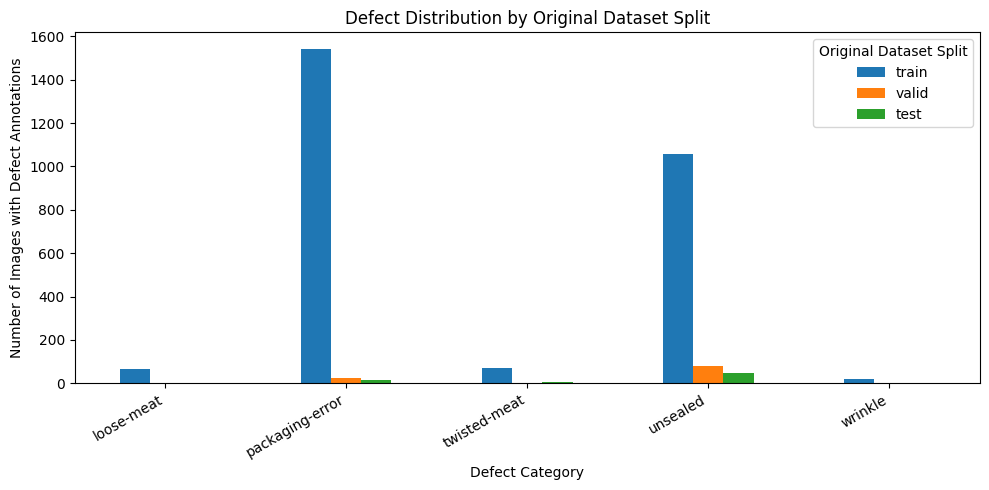

In [10]:
# ============================================================
# VISUALISE DEFECT DISTRIBUTION BY ORIGINAL DATASET SPLIT
# ============================================================

# Restructure image-level defect counts for comparison.
# Rows represent defect categories and columns represent
# the original training, validation and testing partitions.
plot_data = distribution_df.pivot(
    index="Defect",
    columns="Split",
    values="Positive images"
)

# Maintain a consistent order for the original dataset partitions.
plot_data = plot_data[["train", "valid", "test"]]

# Generate a grouped bar chart showing positive image counts.
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

# Label the chart and its axes.
ax.set_title("Defect Distribution by Original Dataset Split")
ax.set_ylabel("Number of Images with Defect Annotations")
ax.set_xlabel("Defect Category")

# Identify the original dataset partitions in the legend.
ax.legend(title="Original Dataset Split")

# Rotate category labels to improve readability.
plt.xticks(rotation=30, ha="right")

# Adjust the layout to prevent labels from being cut off.
plt.tight_layout()

# Display the completed chart.
plt.show()

In [11]:
# ============================================================
# SET PROJECT WORKING DIRECTORY AND PYTHON IMPORT PATH
# ============================================================

import os

# Set the working directory to the project root identified
# during setup, ensuring consistent relative file paths.
os.chdir(project_dir)

# Confirm the current working directory.
print("Current working directory:", os.getcwd())

# Allow Python to locate and import custom modules from src/.
import sys

project_path = str(project_dir)

# Add the project root to Python's module search path
# only if it has not already been included.
if project_path not in sys.path:
    sys.path.insert(0, project_path)

# Confirm the project path used for module imports.
print("Python project path:", project_path)

Current working directory: /content/MMA3001-Pork-Packaging-Analysis
Python project path: /content/MMA3001-Pork-Packaging-Analysis


In [12]:
# ============================================================
# INSTALL PROJECT DEPENDENCIES
# ============================================================

# Install the required Python packages from requirements.txt.
# This ensures the libraries used for image processing,
# numerical calculations, regression and evaluation are available.

# The requirements file is located in the project root,
# which was set as the working directory earlier.

# Use -q to minimise unnecessary installation output.
%pip install -q -r requirements.txt

In [13]:
# ============================================================
# RUN AUTOMATED PREPROCESSING TESTS
# ============================================================

# Use pytest to verify the image feature extraction functions.
# Tests cover uniform images, missing files, valid numerical
# outputs and the expected number of regional features.

# Run the preprocessing test file from the repository's tests/ folder.
# The -v option displays the result of each individual test.
%run -m pytest tests/test_preprocessing.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/MMA3001-Pork-Packaging-Analysis
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collecting ... collected 4 items

tests/test_preprocessing.py::test_uniform_image PASSED                   [ 25%]
tests/test_preprocessing.py::test_missing_image PASSED                   [ 50%]
tests/test_preprocessing.py::test_feature_values PASSED                  [ 75%]
tests/test_preprocessing.py::test_regional_features PASSED               [100%]

============================== 4 passed in 0.11s ===============================


In [14]:
# ============================================================
# ANALYSE DEFECT ANNOTATIONS BY CATEGORY ID
# ============================================================

# Store annotation counts and unique image counts for each defect.
# Keep category IDs separate, including duplicate "packaging-error" names.
results = []

# Analyse the original training, validation and testing partitions.
for split in ["train", "valid", "test"]:

    # Reuse previously loaded COCO annotation data.
    data = datasets[split]

    # Count all annotations belonging to each category ID.
    # Multiple annotations may occur within the same image.
    annotation_counts = Counter(
        annotation["category_id"]
        for annotation in data["annotations"]
    )

    # Store the number of unique images containing each defect category.
    image_counts = {}

    for category in data["categories"]:

        category_id = category["id"]

        # Use a set to prevent counting repeated annotations
        # of the same defect within an image more than once.
        image_ids = {
            annotation["image_id"]
            for annotation in data["annotations"]
            if annotation["category_id"] == category_id
        }

        image_counts[category_id] = len(image_ids)

        # Record the category ID, defect name and associated counts.
        results.append({
            "Split": split,
            "Class ID": category_id,
            "Class Name": category["name"],
            "Annotations": annotation_counts[category_id],
            "Images with class": image_counts[category_id]
        })

# Convert the collected statistics into a structured table.
class_summary = pd.DataFrame(results)

# Display annotation and unique image counts for each category ID.
display(class_summary)

,Split,Class ID,Class Name,Annotations,Images with class
0,train,0,packaging-error,0,0
1,train,1,loose-meat,66,66
2,train,2,packaging-error,1712,1541
3,train,3,twisted-meat,72,69
4,train,4,unsealed,1055,1055
5,train,5,wrinkle,18,18
6,valid,0,packaging-error,0,0
7,valid,1,loose-meat,3,3
8,valid,2,packaging-error,34,23
9,valid,3,twisted-meat,3,3


In [15]:
# ============================================================
# ANALYSE NUMBER OF ANNOTATIONS PER IMAGE
# ============================================================

# Examine annotation counts across the original dataset partitions.
# Identify images with no annotations, one annotation or multiple annotations.
for split in ["train", "valid", "test"]:

    # Access the previously loaded COCO annotation data.
    data = datasets[split]

    # Count the number of annotations associated with each image ID.
    annotation_counts = Counter(
        annotation["image_id"]
        for annotation in data["annotations"]
    )

    # Include all images, assigning zero to those without annotations.
    counts = [
        annotation_counts.get(image["id"], 0)
        for image in data["images"]
    ]

    # Calculate the number of images in each annotation category.
    no_annotations = sum(count == 0 for count in counts)
    one_annotation = sum(count == 1 for count in counts)
    multiple_annotations = sum(count > 1 for count in counts)

    # Display the annotation distribution for each original partition.
    print(f"\n{split.upper()}")
    print("Images with no annotations:", no_annotations)
    print("Images with one annotation:", one_annotation)
    print("Images with multiple annotations:", multiple_annotations)


TRAIN
Images with no annotations: 684
Images with one annotation: 2431
Images with multiple annotations: 234

VALID
Images with no annotations: 14
Images with one annotation: 95
Images with multiple annotations: 11

TEST
Images with no annotations: 12
Images with one annotation: 59
Images with multiple annotations: 9


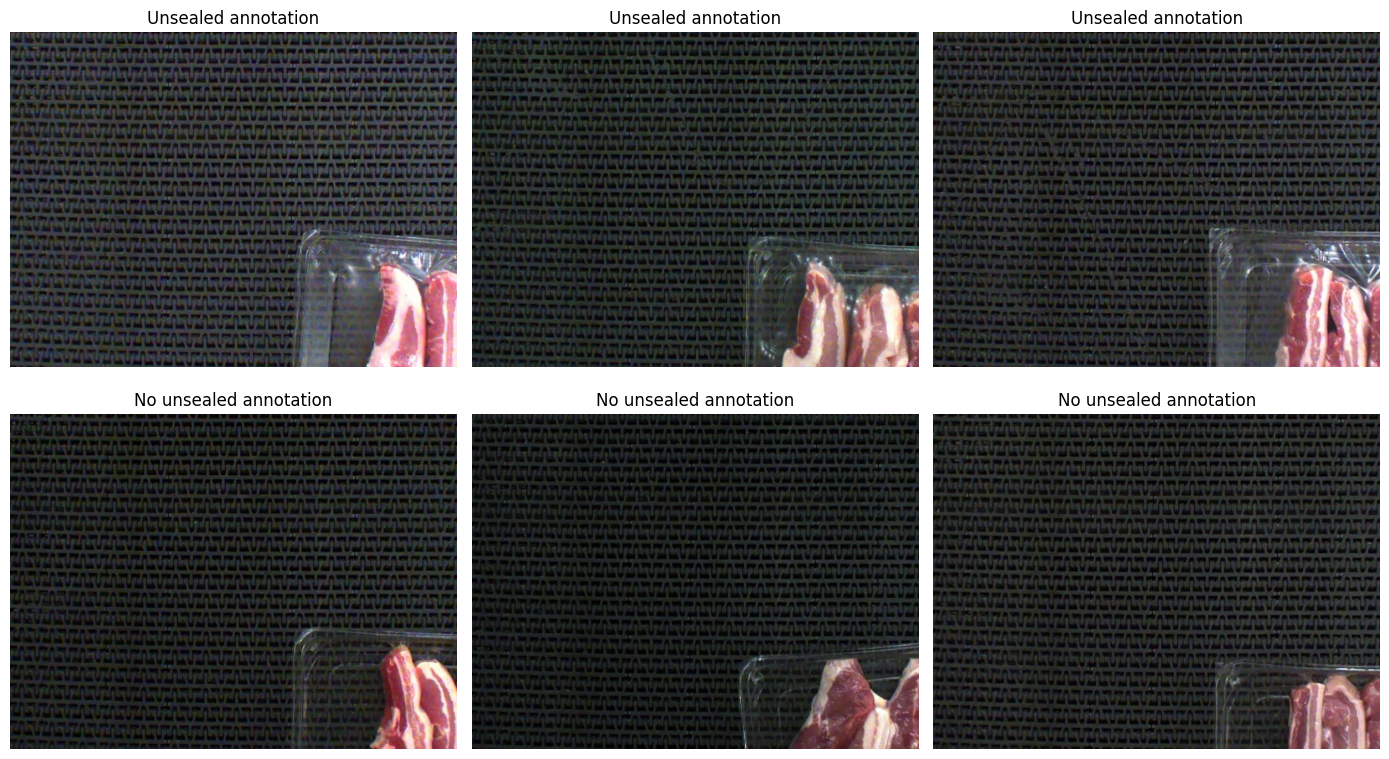

In [16]:
# ============================================================
# VISUALISE POSITIVE AND NEGATIVE UNSEALED IMAGE EXAMPLES
# ============================================================

import random

# Set a fixed random seed for reproducible image selection.
random.seed(42)

# Access the original training images and COCO annotations.
split_path = dataset_folder / "train"
data = datasets["train"]

# Identify the category ID assigned to the "unsealed" defect.
unsealed_id = next(
    category["id"]
    for category in data["categories"]
    if category["name"] == "unsealed"
)

# Collect unique image IDs containing an unsealed annotation.
unsealed_images = {
    annotation["image_id"]
    for annotation in data["annotations"]
    if annotation["category_id"] == unsealed_id
}

# Separate images according to the presence of an unsealed annotation.
positive = [
    image_info
    for image_info in data["images"]
    if image_info["id"] in unsealed_images
]

# Negative images have no unsealed annotation but may contain other defects.
negative = [
    image_info
    for image_info in data["images"]
    if image_info["id"] not in unsealed_images
]

# Verify that sufficient examples are available for visual inspection.
if len(positive) < 3 or len(negative) < 3:
    raise ValueError(
        "At least three positive and three negative "
        "images are required for visual inspection."
    )

# Randomly select three positive and three negative examples.
samples = (
    random.sample(positive, 3)
    + random.sample(negative, 3)
)

# Create a 2 × 3 grid to compare the selected images.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, image_info in enumerate(samples):

    # Locate and load the original image using its COCO filename.
    image_path = split_path / image_info["file_name"]

    # Convert to RGB for correct colour display.
    with Image.open(image_path) as image_file:
        image = image_file.convert("RGB")

    # Display the image in its corresponding subplot.
    ax = axes.flat[i]
    ax.imshow(image)

    # Label positive images in the first row and negative images in the second.
    label = (
        "Unsealed annotation"
        if i < 3
        else "No unsealed annotation"
    )

    ax.set_title(label)
    ax.axis("off")

# Adjust spacing and display the image comparison.
plt.tight_layout()
plt.show()

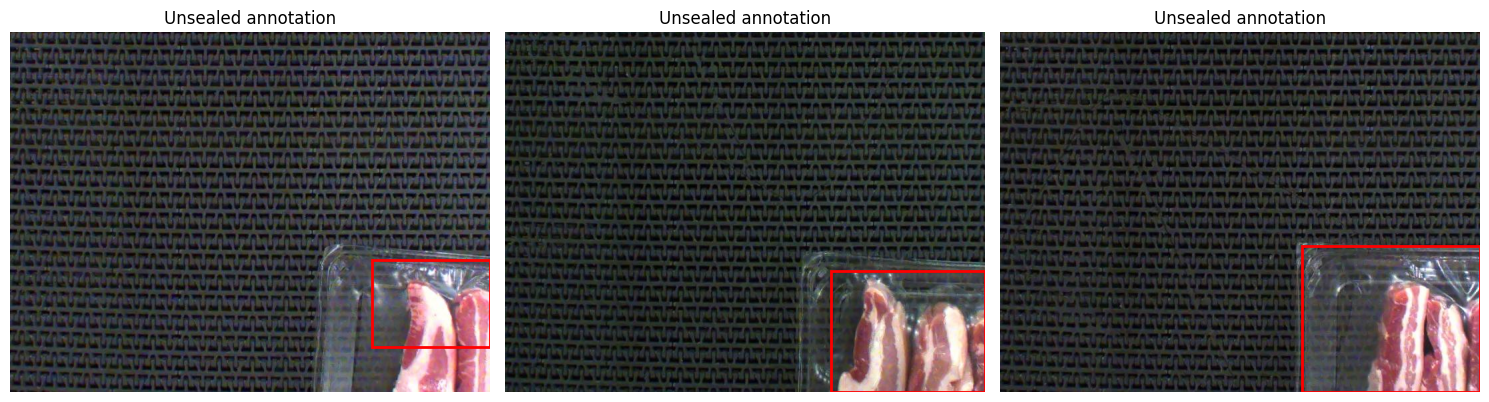

In [17]:
# ============================================================
# VISUALISE UNSEALED DEFECT BOUNDING BOXES
# ============================================================

import matplotlib.patches as patches

# Display the existing COCO bounding boxes for three positive images.
# These are dataset annotations, not predictions from the regression model.

# Group annotations by image ID for efficient retrieval.
# Each image may contain multiple defect annotations.
annotations_by_image = {}

for annotation in data["annotations"]:

    # Store each annotation under its corresponding image ID.
    annotations_by_image.setdefault(
        annotation["image_id"], []
    ).append(annotation)

# Create three subplots for the positive examples selected previously.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image_info in zip(axes, samples[:3]):

    # Locate and load the original image using its COCO filename.
    image_path = split_path / image_info["file_name"]

    # Convert the image to RGB for correct colour display.
    with Image.open(image_path) as image_file:
        image = image_file.convert("RGB")

    ax.imshow(image)

    # Retrieve all annotations associated with the current image.
    for annotation in annotations_by_image.get(
        image_info["id"], []
    ):

        # Display only bounding boxes belonging to the unsealed category.
        if annotation["category_id"] != unsealed_id:
            continue

        # Extract COCO bounding-box coordinates in pixels:
        # x and y specify the top-left corner; w and h specify size.
        x, y, w, h = annotation["bbox"]

        # Draw a red rectangle around the annotated unsealed region.
        rectangle = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

    # Label each image and remove axis ticks.
    ax.set_title("Unsealed annotation")
    ax.axis("off")

# Adjust the layout and display the annotated images.
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# BUILD NUMERICAL IMAGE FEATURE TABLES
# ============================================================

# Import reusable functions for loading image records and
# extracting whole-image or regional numerical features.
from src.data_loader import create_image_records
from src.preprocessing import (
    extract_image_features,
    extract_regional_features
)

# Define the target defect category for binary classification.
# Label 1 indicates an unsealed annotation; label 0 indicates
# no recorded unsealed annotation.
target_class = "unsealed"


def build_feature_table(split, method="whole"):
    """
    Create a numerical feature table for an original dataset partition.

    Args:
        split (str): Original partition: 'train', 'valid' or 'test'.
        method (str): 'whole' for four image features or
            'regional' for 36 features extracted from a 3 x 3 grid.

    Returns:
        pandas.DataFrame: Image IDs, binary labels and numerical
            feature columns, with one row per image.

    Raises:
        ValueError: If the split or extraction method is unsupported.
        FileNotFoundError: If required dataset files are missing.

    Notes:
        This function processes the original Roboflow partitions.
        Final modelling uses the corrected dataset manifest.
    """

    # Check that the requested dataset partition is supported.
    if split not in ("train", "valid", "test"):
        raise ValueError(
            "split must be 'train', 'valid' or 'test'."
        )

    # Check that a valid feature extraction method was selected.
    if method not in ("whole", "regional"):
        raise ValueError(
            "method must be 'whole' or 'regional'."
        )

    # Locate the original image directory and COCO annotation file.
    split_folder = dataset_folder / split

    # Load image records and their annotation-derived binary labels.
    records = create_image_records(
        image_folder=split_folder,
        annotation_path=(
            split_folder / "_annotations.coco.json"
        ),
        target_class=target_class
    )

    # Store the numerical measurements for each image.
    rows = []

    for record in records:

        # Extract four features from the whole image or
        # 36 features from nine image regions.
        if method == "whole":
            features = extract_image_features(
                record["image_path"]
            )
        else:
            features = extract_regional_features(
                record["image_path"],
                grid_size=3
            )

        # Preserve the image identifier and binary target label.
        row = {
            "image_id": record["image_id"],
            "label": record["label"]
        }

        # Add each numerical measurement as a separate feature column.
        for i, value in enumerate(features):
            row[f"feature_{i+1}"] = float(value)

        rows.append(row)

    # Return a DataFrame ready for regression analysis.
    return pd.DataFrame(rows)


# Import additional reusable functions for COCO annotation handling.
from src.data_loader import (
    load_coco_annotations,
    create_image_records
)

In [19]:
# ============================================================
# GENERATE WHOLE-IMAGE AND REGIONAL FEATURE TABLES
# ============================================================

# Extract four whole-image features from the original training
# and validation images: brightness, contrast, saturation and edge density.
train_whole = build_feature_table("train", "whole")
valid_whole = build_feature_table("valid", "whole")

# Extract 36 regional features using a 3 × 3 image grid.
# Each of the nine regions contributes four numerical measurements.
train_regional = build_feature_table("train", "regional")
valid_regional = build_feature_table("valid", "regional")

# Display table dimensions to confirm the number of images and features.
# Each table also contains an image ID and binary target label.
print("Whole-image training:", train_whole.shape)
print("Whole-image validation:", valid_whole.shape)

print("Regional training:", train_regional.shape)
print("Regional validation:", valid_regional.shape)

# Preview five regional training records to inspect labels and feature values.
display(train_regional.head())

Whole-image training: (3349, 6)
Whole-image validation: (120, 6)
Regional training: (3349, 38)
Regional validation: (120, 38)


,image_id,label,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36
0,0,0,21.1104,11.170283,56.4197,0.3162,21.1277,12.093899,59.0880,0.3430,...,57.3849,0.1221,22.1087,12.790570,54.3628,0.2260,81.1765,64.493827,66.5483,0.2130
1,1,1,20.5017,10.619171,103.2974,0.2802,20.8940,11.669343,102.7457,0.3233,...,101.1910,0.0765,22.0231,11.762617,97.3890,0.2023,94.3787,55.870005,93.3947,0.1762
2,2,1,20.0477,10.446465,83.9158,0.2395,20.1485,11.697574,85.5919,0.3263,...,83.7029,0.0706,21.9508,13.547663,80.6875,0.2057,78.0852,69.692521,80.9584,0.1600
3,3,0,41.7220,21.697611,52.8016,0.3499,37.3109,17.750872,57.9776,0.3643,...,87.5888,0.2266,52.0434,37.515574,53.1097,0.2934,39.9988,16.273991,53.9251,0.3369
4,4,0,39.4231,18.967627,55.5778,0.3607,37.8824,17.555796,58.2415,0.3589,...,77.3116,0.1791,86.0555,68.683679,59.7715,0.2520,40.8572,16.475327,52.4676,0.3340


In [20]:
# ============================================================
# CHECK FEATURE COMPLETENESS AND CLASS DISTRIBUTION
# ============================================================

# Examine the four feature tables from the original Roboflow
# training and validation partitions, before data correction.
feature_tables = [
    ("Training whole", train_whole),
    ("Validation whole", valid_whole),
    ("Training regional", train_regional),
    ("Validation regional", valid_regional)
]

for name, df in feature_tables:

    # Display the dataset name and dimensions (rows, columns).
    print(f"\n{name}")
    print("Shape:", df.shape)

    # Count missing values to check feature table completeness.
    missing_values = df.isna().sum().sum()
    print("Missing values:", missing_values)

    # Count images belonging to each binary target class.
    # 0 = No unsealed annotation; 1 = Unsealed annotation present.
    label_counts = df["label"].value_counts().sort_index()

    print("Label counts:")
    print(label_counts)

    # Calculate class percentages to identify potential imbalance.
    label_percentages = (
        df["label"].value_counts(normalize=True)
        .sort_index() * 100
    )

    # Display the percentage distribution rounded to two decimals.
    print("Label percentages:")
    print(label_percentages.round(2))


Training whole
Shape: (3349, 6)
Missing values: 0
Label counts:
label
0    2294
1    1055
Name: count, dtype: int64
Label percentages:
label
0    68.5
1    31.5
Name: proportion, dtype: float64

Validation whole
Shape: (120, 6)
Missing values: 0
Label counts:
label
0    39
1    81
Name: count, dtype: int64
Label percentages:
label
0    32.5
1    67.5
Name: proportion, dtype: float64

Training regional
Shape: (3349, 38)
Missing values: 0
Label counts:
label
0    2294
1    1055
Name: count, dtype: int64
Label percentages:
label
0    68.5
1    31.5
Name: proportion, dtype: float64

Validation regional
Shape: (120, 38)
Missing values: 0
Label counts:
label
0    39
1    81
Name: count, dtype: int64
Label percentages:
label
0    32.5
1    67.5
Name: proportion, dtype: float64


In [21]:
# ============================================================
# DETECT EXACT DUPLICATE IMAGES USING SHA-256
# ============================================================

import hashlib
from collections import defaultdict


def get_image_hashes(split):
    """
    Generate SHA-256 hashes for images in an original dataset partition.

    Args:
        split (str): Original partition: 'train', 'valid' or 'test'.

    Returns:
        dict: SHA-256 hashes mapped to their corresponding image paths.
            Multiple paths sharing a hash indicate identical file contents.

    Raises:
        ValueError: If an unsupported partition is specified.
        FileNotFoundError: If required dataset files cannot be found.

    Notes:
        SHA-256 identifies byte-for-byte duplicates, not visually
        similar images or neighbouring production-line frames.
    """

    # Check that the requested original dataset partition is valid.
    if split not in ("train", "valid", "test"):
        raise ValueError(
            "split must be 'train', 'valid' or 'test'."
        )

    # Locate the original image directory and COCO annotations.
    folder = dataset_folder / split

    # Load image records from the selected partition.
    records = create_image_records(
        folder,
        folder / "_annotations.coco.json",
        target_class="unsealed"
    )

    # Group image paths according to their SHA-256 hashes.
    hashes = defaultdict(list)

    for record in records:

        # Read the file bytes and calculate a unique content digest.
        with open(record["image_path"], "rb") as file:
            digest = hashlib.sha256(file.read()).hexdigest()

        # Record the image path associated with each hash.
        hashes[digest].append(record["image_path"])

    return hashes


# Calculate image hashes for each original dataset partition.
train_hashes = get_image_hashes("train")
valid_hashes = get_image_hashes("valid")
test_hashes = get_image_hashes("test")

# Count shared hashes between partitions to detect exact duplicates.
train_valid_duplicates = len(
    set(train_hashes) & set(valid_hashes)
)

train_test_duplicates = len(
    set(train_hashes) & set(test_hashes)
)

valid_test_duplicates = len(
    set(valid_hashes) & set(test_hashes)
)

# Display duplicate counts to assess potential data leakage.
print("Train/validation duplicates:", train_valid_duplicates)
print("Train/test duplicates:", train_test_duplicates)
print("Validation/test duplicates:", valid_test_duplicates)

Train/validation duplicates: 0
Train/test duplicates: 0
Validation/test duplicates: 0


In [22]:
# ============================================================
# PREPARE REGRESSION INPUTS AND TARGET LABELS
# ============================================================

# Import reusable functions for regression training and evaluation.
from src.regression import (
    train_linear_regression,
    train_decision_tree
)

from src.evaluation import evaluate_model


def prepare_xy(df):
    """
    Separate numerical image features from binary target labels.

    Args:
        df (pandas.DataFrame): Feature table containing a 'label'
            column and numerical columns named 'feature_1', etc.

    Returns:
        tuple: (X, y), where X is a two-dimensional NumPy array
            of image features and y is a one-dimensional array
            of binary target labels (0 or 1).

    Raises:
        ValueError: If no feature columns are found.
        KeyError: If the required 'label' column is missing.

    Notes:
        Image identifiers are excluded from model inputs.
        The original row order is preserved.
    """

    # Select numerical feature columns, excluding image IDs and labels.
    feature_columns = [
        col for col in df.columns
        if col.startswith("feature_")
    ]

    # Ensure that the dataset contains at least one input feature.
    if not feature_columns:
        raise ValueError(
            "No feature columns were found in the DataFrame."
        )

    # Convert numerical features into a two-dimensional input matrix.
    X = df[feature_columns].to_numpy()

    # Extract the binary unsealed-annotation labels.
    y = df["label"].to_numpy()

    return X, y


# Prepare the original training and validation data using four
# whole-image features per image.
X_train_whole, y_train = prepare_xy(train_whole)
X_valid_whole, y_valid = prepare_xy(valid_whole)

# Prepare the same images using 36 regional features per image.
X_train_regional, _ = prepare_xy(train_regional)
X_valid_regional, _ = prepare_xy(valid_regional)

# Confirm the dimensions of both feature representations.
print("Whole image:", X_train_whole.shape)
print("Regional:", X_train_regional.shape)

# Verify that both methods preserve identical image ordering.
assert train_whole["image_id"].equals(
    train_regional["image_id"]
), "Training image order differs between feature tables."

assert valid_whole["image_id"].equals(
    valid_regional["image_id"]
), "Validation image order differs between feature tables."

# Confirm that whole-image and regional target labels match.
# This allows both feature representations to share the same labels.
assert train_whole["label"].equals(
    train_regional["label"]
), "Training labels differ between feature tables."

assert valid_whole["label"].equals(
    valid_regional["label"]
), "Validation labels differ between feature tables."

# Confirm that feature arrays and target labels are correctly aligned.
print("Whole-image and regional labels are aligned.")

Whole image: (3349, 4)
Regional: (3349, 36)
Whole-image and regional labels are aligned.


In [23]:
# ============================================================
# COMPARE REGRESSION MODELS AND FEATURE EXTRACTION METHODS
# ============================================================

# Define four preliminary experiments combining two regression
# methods (linear and decision tree) with two feature representations
# (four whole-image features and 36 regional features).
#
# These experiments use the original Roboflow partitions.
# Final model evaluation uses the corrected dataset.

experiments = {
    "Linear - Whole": (
        train_linear_regression,
        X_train_whole,
        X_valid_whole
    ),
    "Linear - Regional": (
        train_linear_regression,
        X_train_regional,
        X_valid_regional
    ),
    "Tree - Whole": (
        train_decision_tree,
        X_train_whole,
        X_valid_whole
    ),
    "Tree - Regional": (
        train_decision_tree,
        X_train_regional,
        X_valid_regional
    )
}

# Store trained models and their corresponding evaluation metrics.
models = {}
evaluation_results = []

# Train and evaluate each combination of model and feature method.
for name, (train_function, X_train, X_valid) in experiments.items():

    # Train the selected regression model using known binary labels.
    model = train_function(X_train, y_train)

    # Predict continuous scores for the original validation images.
    scores = model.predict(X_valid)

    # Apply a consistent threshold of 0.50 and calculate
    # performance metrics for the preliminary comparison.
    metrics = evaluate_model(
        y_valid,
        scores,
        threshold=0.5
    )

    # Preserve each trained model for possible later inspection.
    models[name] = model

    # Record the experiment name and its evaluation results.
    evaluation_results.append({
        "Model": name,
        **metrics
    })

# Convert the collected metrics into a comparison table.
results_df = pd.DataFrame(evaluation_results)

# Display results to three decimal places without changing
# the underlying numerical values.
display(results_df.round(3))

,Model,MAE,MSE,Accuracy,Precision,Recall,F1,TP,TN,FP,FN
0,Linear - Whole,0.562,0.344,0.325,0.000,0.000,0.000,0,39,0,81
1,Linear - Regional,0.341,0.171,0.717,0.912,0.642,0.754,52,34,5,29
2,Tree - Whole,0.530,0.313,0.508,0.824,0.346,0.487,28,33,6,53
3,Tree - Regional,0.444,0.294,0.592,0.767,0.568,0.652,46,25,14,35


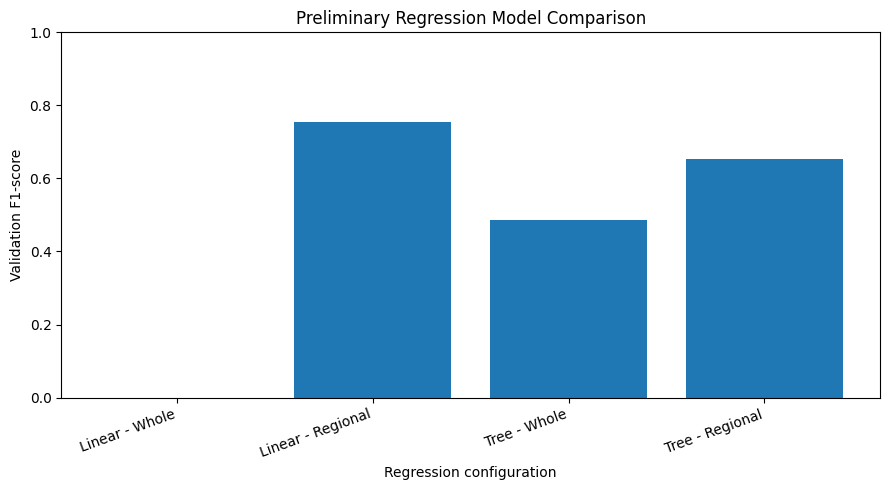

In [24]:
# ============================================================
# VISUALISE PRELIMINARY REGRESSION MODEL PERFORMANCE
# ============================================================

# Compare validation F1-scores for the four regression
# configurations evaluated using the original dataset partitions.
# F1-score measures the balance between precision and recall.

# Create a figure for comparing model performance.
plt.figure(figsize=(9, 5))

# Plot the F1-score for each regression and feature combination.
plt.bar(
    results_df["Model"],
    results_df["F1"]
)

# Add descriptive labels and a chart title.
plt.ylabel("Validation F1-score")
plt.xlabel("Regression configuration")
plt.title("Preliminary Regression Model Comparison")

# Set the F1-score axis from 0 to 1 for consistent interpretation.
plt.ylim(0, 1)

# Rotate model names to improve readability.
plt.xticks(rotation=20, ha="right")

# Adjust spacing to prevent overlapping or clipped labels.
plt.tight_layout()

# Display the model comparison chart.
plt.show()

In [25]:
# ============================================================
# PRELIMINARY CLASSIFICATION THRESHOLD ANALYSIS
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

# Investigate how classification thresholds affect the regional
# linear regression model using the original Roboflow partitions.
# These preliminary results may be affected by related frames
# appearing in both training and validation datasets.

# Retrieve the linear regression model trained on 3,349 original images.
model = models["Linear - Regional"]

# Generate continuous prediction scores for 120 validation images.
scores = model.predict(X_valid_regional)

# Store classification metrics for each threshold.
threshold_results = []

# Evaluate thresholds from 0.10 to 0.90 in increments of 0.05.
# Lower thresholds generally increase recall but may increase
# false positives; higher thresholds may increase false negatives.
for threshold in np.arange(0.10, 0.91, 0.05):

    # Calculate classification performance at the current threshold.
    metrics = evaluate_model(
        y_valid,
        scores,
        threshold=threshold
    )

    # Record the metrics needed to compare threshold performance.
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "False Negatives": metrics["FN"],
        "False Positives": metrics["FP"]
    })

# Convert the results into a structured comparison table.
threshold_df = pd.DataFrame(threshold_results)

# Display results rounded to three decimal places.
display(threshold_df.round(3))


# ============================================================
# INTERPRETATION OF PRELIMINARY RESULTS
# ============================================================

# The highest preliminary validation F1-score was approximately
# 0.880 at threshold 0.25.

# These results are not used for final model selection because
# the original dataset partitions contain potentially related frames,
# creating a risk of sequence-related data leakage.

# The subsequent corrected dataset contains:
# Training:   2,667 images
# Validation:   369 images
# Testing:      418 images

# The model is retrained and its threshold is selected again
# using the corrected training and validation partitions.
# The corrected experiment selected threshold 0.30.

# The preliminary threshold of 0.25 is not transferred to the
# final model because the training and validation data differ.

# The corrected testing partition remains withheld until
# final evaluation and is not used for parameter selection.

,Threshold,Accuracy,Precision,Recall,F1,False Negatives,False Positives
0,0.10,0.775,0.760,0.975,0.854,2,25
1,0.15,0.800,0.788,0.963,0.867,3,21
2,0.20,0.817,0.804,0.963,0.876,3,19
3,0.25,0.825,0.819,0.951,0.880,4,17
4,0.30,0.825,0.841,0.914,0.876,7,14
5,0.35,0.825,0.875,0.864,0.870,11,10
6,0.40,0.750,0.870,0.741,0.800,21,9
7,0.45,0.725,0.900,0.667,0.766,27,6
8,0.50,0.717,0.912,0.642,0.754,29,5
9,0.55,0.692,0.940,0.580,0.718,34,3


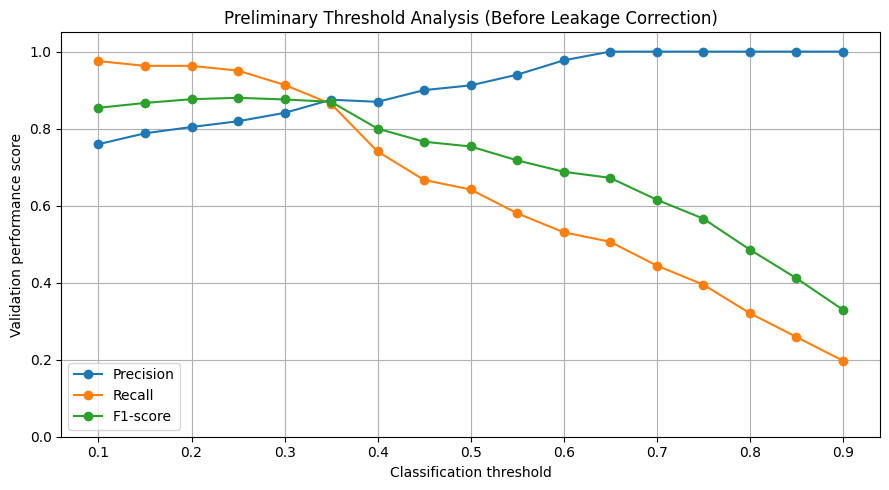

In [26]:
# ============================================================
# VISUALISE PRELIMINARY CLASSIFICATION THRESHOLD PERFORMANCE
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

# Compare precision, recall and F1-score across classification
# thresholds using the original Roboflow validation dataset.
# These results are preliminary because potential data leakage
# between closely related frames has not yet been addressed.

# Create a figure to display the three performance metrics.
plt.figure(figsize=(9, 5))

# Plot precision: proportion of predicted unsealed images
# that contain an unsealed annotation.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

# Plot recall: proportion of annotated unsealed images
# correctly identified by the model.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

# Plot F1-score: harmonic mean of precision and recall.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

# Add descriptive labels and identify the preliminary experiment.
plt.xlabel("Classification threshold")
plt.ylabel("Validation performance score")
plt.title("Preliminary Threshold Analysis (Before Leakage Correction)")

# Set a consistent vertical scale for the performance metrics.
plt.ylim(0, 1.05)

# Display the legend and grid to improve readability.
plt.legend()
plt.grid(True)

# Adjust spacing and display the comparison graph.
plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# EVALUATE THE PRELIMINARY ALWAYS-UNSEALED BASELINE
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

# Establish a simple reference model that predicts every image
# as unsealed, regardless of its numerical image features.
# This requires no model training.

# Use the original Roboflow validation partition (120 images).
# Results are preliminary and will be reassessed using corrected data.

# Assign a constant prediction score of 1 to every validation image.
always_unsealed = np.ones(len(y_valid))

# Evaluate the baseline using the same metrics and threshold
# applied to the preliminary regression models.
baseline = evaluate_model(
    y_valid,
    always_unsealed,
    threshold=0.5
)

# Display baseline performance for comparison with regression models.
print("Always-unsealed baseline (original validation set):")
print(baseline)

Always-unsealed baseline (original validation set):
{'MAE': 0.325, 'MSE': 0.325, 'Accuracy': 0.675, 'Precision': 0.675, 'Recall': 1.0, 'F1': 0.8059701492537313, 'TP': 81, 'TN': 0, 'FP': 39, 'FN': 0}


In [28]:
# ============================================================
# PRELIMINARY DECISION TREE DEPTH AND THRESHOLD OPTIMISATION
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

from sklearn.tree import DecisionTreeRegressor

# Investigate how tree depth and classification threshold affect
# performance using the original Roboflow training (3,349 images)
# and validation (120 images) partitions.
# Results are preliminary because potential data leakage remains.

# Store evaluation metrics for each tested configuration.
depth_results = []

# Test a range of maximum tree depths.
# Shallow trees may underfit, while deeper trees may overfit.
for depth in [2, 3, 4, 5, 6, 8, 10, 15]:

    # Initialise a decision tree with a fixed random seed
    # to support reproducible model training.
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Train using 36 regional features and binary target labels.
    model.fit(X_train_regional, y_train)

    # Generate numerical prediction scores for validation images.
    scores = model.predict(X_valid_regional)

    # Compare classification thresholds for each trained tree.
    # The model is trained once per depth.
    for threshold in [0.2, 0.25, 0.3, 0.4, 0.5]:

        # Calculate classification metrics for the current settings.
        metrics = evaluate_model(
            y_valid,
            scores,
            threshold=threshold
        )

        # Record tree depth, threshold and performance metrics.
        depth_results.append({
            "Depth": depth,
            "Threshold": threshold,
            "Accuracy": metrics["Accuracy"],
            "Precision": metrics["Precision"],
            "Recall": metrics["Recall"],
            "F1": metrics["F1"],
            "FN": metrics["FN"],
            "FP": metrics["FP"]
        })

# Organise all tested configurations into a DataFrame.
tree_optimisation = pd.DataFrame(depth_results)

# Display the 15 configurations with the highest F1-scores.
# The complete results remain stored for further analysis.
display(
    tree_optimisation.sort_values(
        "F1", ascending=False
    ).head(15).round(3)
)

,Depth,Threshold,Accuracy,Precision,Recall,F1,FN,FP
0,2,0.20,0.725,0.731,0.938,0.822,5,28
1,2,0.25,0.725,0.731,0.938,0.822,5,28
2,2,0.30,0.725,0.731,0.938,0.822,5,28
5,3,0.20,0.725,0.731,0.938,0.822,5,28
6,3,0.25,0.725,0.731,0.938,0.822,5,28
11,4,0.25,0.700,0.771,0.790,0.780,17,19
10,4,0.20,0.700,0.771,0.790,0.780,17,19
20,6,0.20,0.683,0.753,0.790,0.771,17,21
15,5,0.20,0.667,0.730,0.802,0.765,16,24
21,6,0.25,0.675,0.756,0.765,0.761,19,20


In [29]:
# ============================================================
# COMPARE OPTIMISED PRELIMINARY REGRESSION MODELS
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

# Compare the best decision tree and linear regression configurations
# using the original Roboflow validation dataset.
# Results are preliminary because potential data leakage remains.

# Select the decision tree with the highest validation F1-score.
# Use recall as a tie-breaker to prioritise fewer missed defects.
best_tree = tree_optimisation.sort_values(
    ["F1", "Recall"],
    ascending=[False, False]
).iloc[0]

# Select the best linear regression threshold using the
# same F1-score and recall selection criteria.
best_linear = threshold_df.sort_values(
    ["F1", "Recall"],
    ascending=[False, False]
).iloc[0]

# Display the selected preliminary decision tree configuration.
print("BEST PRELIMINARY DECISION TREE")
print("Maximum depth:", int(best_tree["Depth"]))
print("Threshold:", f'{best_tree["Threshold"]:.2f}')
print("Validation F1:", f'{best_tree["F1"]:.3f}')
print("Validation recall:", f'{best_tree["Recall"]:.3f}')
print("False negatives:", int(best_tree["FN"]))
print("False positives:", int(best_tree["FP"]))

# Display the selected preliminary linear regression configuration.
print("\nBEST PRELIMINARY LINEAR REGRESSION")
print("Threshold:", f'{best_linear["Threshold"]:.2f}')
print("Validation F1:", f'{best_linear["F1"]:.3f}')
print("Validation recall:", f'{best_linear["Recall"]:.3f}')
print(
    "False negatives:",
    int(best_linear["False Negatives"])
)
print(
    "False positives:",
    int(best_linear["False Positives"])
)

# Calculate the difference between the two validation F1-scores.
# A positive value favours linear regression; a negative value
# favours decision tree regression.
f1_difference = best_linear["F1"] - best_tree["F1"]

# Display the preliminary performance difference.
print("\nPRELIMINARY F1 COMPARISON")
print("Linear F1 minus Tree F1:", f"{f1_difference:.3f}")

# Final model selection is performed separately using the
# corrected frame-grouped training and validation partitions.

BEST PRELIMINARY DECISION TREE
Maximum depth: 2
Threshold: 0.20
Validation F1: 0.822
Validation recall: 0.938
False negatives: 5
False positives: 28

BEST PRELIMINARY LINEAR REGRESSION
Threshold: 0.25
Validation F1: 0.880
Validation recall: 0.951
False negatives: 4
False positives: 17

PRELIMINARY F1 COMPARISON
Linear F1 minus Tree F1: 0.058


,Depth,Training MSE,Validation MSE
0,2,0.1945,0.3064
1,3,0.1807,0.3310
2,4,0.1589,0.2953
3,5,0.1449,0.2942
4,6,0.1203,0.2409
5,8,0.0856,0.2941
6,10,0.0484,0.2915
7,15,0.0056,0.3565


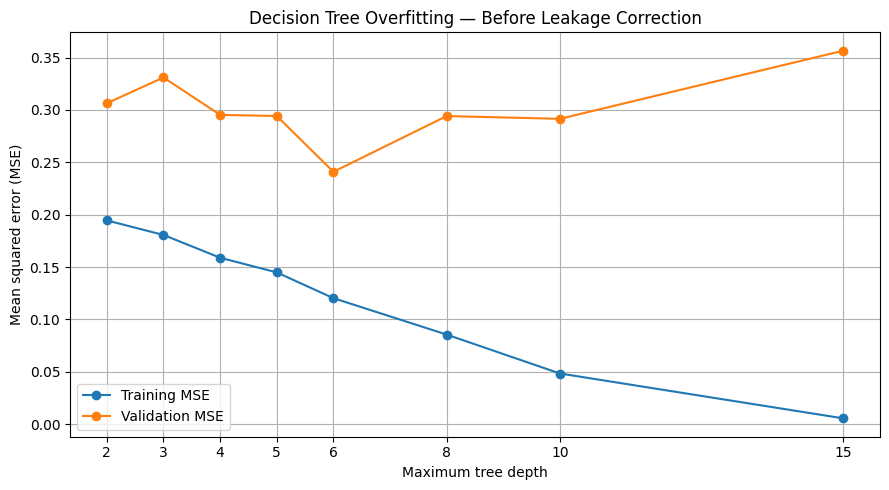

In [30]:
# ============================================================
# INVESTIGATE PRELIMINARY DECISION TREE OVERFITTING
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

from sklearn.metrics import mean_squared_error

# Compare training and validation MSE across different tree depths.
# This experiment uses the original Roboflow partitions, before
# correcting potential data leakage between related frames.

# Define the maximum tree depths to investigate.
depths = [2, 3, 4, 5, 6, 8, 10, 15]

# Store training and validation errors for each configuration.
results = []

for depth in depths:

    # Initialise a decision tree with a fixed depth and random seed.
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Train the model using 36 regional features from the original dataset.
    model.fit(X_train_regional, y_train)

    # Generate continuous predictions for training and validation images.
    train_pred = model.predict(X_train_regional)
    valid_pred = model.predict(X_valid_regional)

    # Calculate the mean squared difference between predicted
    # scores and the corresponding binary target labels.
    results.append({
        "Depth": depth,
        "Training MSE": mean_squared_error(
            y_train, train_pred
        ),
        "Validation MSE": mean_squared_error(
            y_valid, valid_pred
        )
    })

# Convert the calculated errors into a comparison table.
overfitting_df = pd.DataFrame(results)

# Display MSE values rounded to four decimal places.
display(overfitting_df.round(4))


# ============================================================
# VISUALISE TRAINING AND VALIDATION ERROR
# ============================================================

# Plot both error curves to investigate possible overfitting.
plt.figure(figsize=(9, 5))

# Show how training error changes with increasing tree depth.
plt.plot(
    overfitting_df["Depth"],
    overfitting_df["Training MSE"],
    marker="o",
    label="Training MSE"
)

# Show how validation error changes with increasing tree depth.
plt.plot(
    overfitting_df["Depth"],
    overfitting_df["Validation MSE"],
    marker="o",
    label="Validation MSE"
)

# Label the axes and identify the preliminary experiment.
plt.xlabel("Maximum tree depth")
plt.ylabel("Mean squared error (MSE)")
plt.title(
    "Decision Tree Overfitting — Before Leakage Correction"
)

# Display each investigated tree depth.
plt.xticks(depths)

# Add a legend and grid for easier comparison.
plt.legend()
plt.grid(True)

# Adjust spacing and display the completed graph.
plt.tight_layout()
plt.show()


# ============================================================
# INTERPRETATION OF OVERFITTING
# ============================================================

# Increasing tree depth generally allows a closer fit to training data.
# However, lower training MSE does not guarantee better generalisation.

# If training error decreases while validation error increases,
# this suggests that the model may be overfitting.

# Results are preliminary because the original partitions may
# contain related frames. Final conclusions should use the
# corrected frame-grouped training and validation datasets.

Missed unsealed annotations: 4


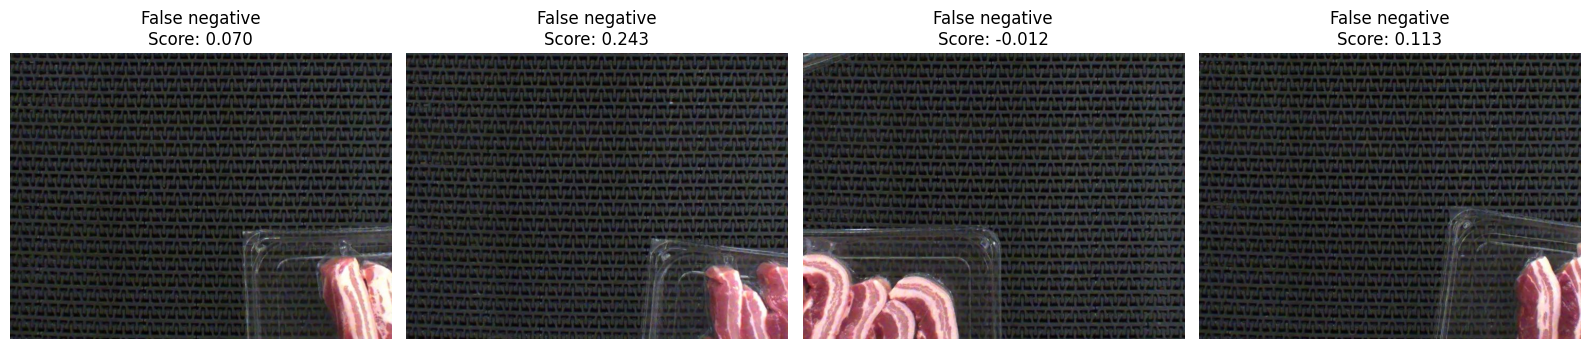

In [31]:
# ============================================================
# VISUALISE PRELIMINARY FALSE NEGATIVE PREDICTIONS
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

# Identify images annotated as unsealed but incorrectly predicted
# as negative by the regional linear regression model.
# This analysis uses the original validation partition (120 images),
# so the results are exploratory rather than final test results.

# Retrieve the previously trained regional linear regression model.
model = models["Linear - Regional"]

# Generate continuous prediction scores for validation images.
scores = model.predict(X_valid_regional)

# Apply the preliminary threshold selected using validation F1-score.
preliminary_threshold = 0.25

# Convert regression scores into binary predictions.
# 1 = unsealed predicted; 0 = no unsealed annotation predicted.
predictions = (scores >= preliminary_threshold).astype(int)

# Identify false negatives: actual label 1, predicted label 0.
false_negative_indices = np.where(
    (y_valid == 1) & (predictions == 0)
)[0]

# Report the number of missed unsealed annotations.
print(
    "Missed unsealed annotations:",
    len(false_negative_indices)
)

# Load original validation image records for visual inspection.
valid_folder = dataset_folder / "valid"

valid_records = create_image_records(
    valid_folder,
    valid_folder / "_annotations.coco.json",
    target_class="unsealed"
)

# Verify that image records match the feature table and predictions.
# This prevents displaying incorrect images for identified errors.
assert len(valid_records) == len(valid_regional), (
    "Validation record count does not match the feature table."
)

assert all(
    record["image_id"] == image_id
    and record["label"] == label
    for record, image_id, label in zip(
        valid_records,
        valid_regional["image_id"],
        y_valid
    )
), "Validation image order or labels do not match."

# Display incorrectly classified images if false negatives exist.
if len(false_negative_indices) > 0:

    # Create one subplot for each missed unsealed annotation.
    fig, axes = plt.subplots(
        1,
        len(false_negative_indices),
        figsize=(4 * len(false_negative_indices), 4),
        squeeze=False
    )

    for ax, idx in zip(axes.flat, false_negative_indices):

        # Retrieve the image corresponding to the prediction.
        image_path = valid_records[idx]["image_path"]

        # Open and convert the image to RGB for display.
        with Image.open(image_path) as image_file:
            image = image_file.convert("RGB")

        ax.imshow(image)

        # Display the false negative label and prediction score.
        ax.set_title(
            f"False negative\nScore: {scores[idx]:.3f}"
        )
        ax.axis("off")

    # Adjust spacing and display the images.
    plt.tight_layout()
    plt.show()

else:
    # Report when no annotated unsealed images were missed.
    print("No false negatives at the selected threshold.")

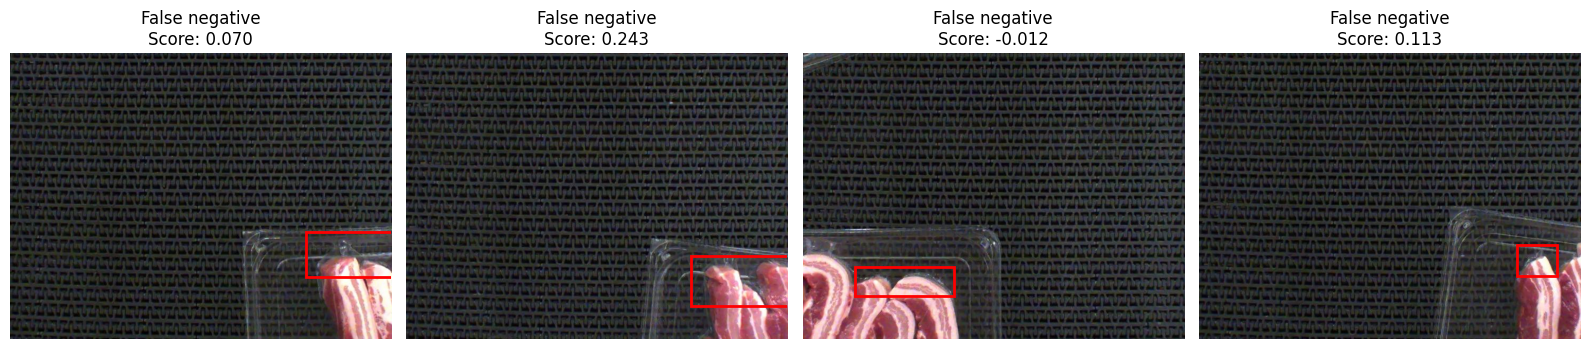

In [32]:
# ============================================================
# VISUALISE PRELIMINARY FALSE NEGATIVES WITH BOUNDING BOXES
# BEFORE DATA LEAKAGE CORRECTION
# ============================================================

import matplotlib.patches as patches

# Display the false-negative images identified previously,
# with their original COCO unsealed-defect bounding boxes.
# These annotations show recorded defect locations, not model predictions.

# Load annotations from the original Roboflow validation partition.
valid_data = load_coco_annotations(
    dataset_folder / "valid" / "_annotations.coco.json"
)

# Identify category IDs associated with the unsealed defect.
unsealed_ids = {
    category["id"]
    for category in valid_data["categories"]
    if category["name"] == "unsealed"
}

# Group unsealed annotations by image ID for efficient lookup.
# Each image may contain multiple annotated unsealed regions.
annotations_by_id = {}

for annotation in valid_data["annotations"]:

    if annotation["category_id"] in unsealed_ids:
        annotations_by_id.setdefault(
            annotation["image_id"], []
        ).append(annotation)


# Check whether the preliminary model produced false negatives.
if len(false_negative_indices) > 0:

    # Create one subplot for each missed unsealed image.
    fig, axes = plt.subplots(
        1,
        len(false_negative_indices),
        figsize=(4 * len(false_negative_indices), 4),
        squeeze=False
    )

    for ax, idx in zip(axes.flat, false_negative_indices):

        # Retrieve the image record corresponding to the prediction.
        record = valid_records[idx]

        # Load and convert the image to RGB for display.
        with Image.open(record["image_path"]) as image_file:
            image = image_file.convert("RGB")

        ax.imshow(image)

        # Retrieve all annotated unsealed regions in this image.
        for annotation in annotations_by_id.get(
            record["image_id"], []
        ):

            # Extract COCO bounding-box coordinates in pixels.
            # (x, y) specifies the top-left corner;
            # (w, h) specifies the box width and height.
            x, y, w, h = annotation["bbox"]

            # Overlay a red rectangle around each annotated defect.
            rectangle = patches.Rectangle(
                (x, y),
                w,
                h,
                fill=False,
                edgecolor="red",
                linewidth=2
            )

            ax.add_patch(rectangle)

        # Show the model's score for each missed annotation.
        ax.set_title(
            f"False negative\nScore: {scores[idx]:.3f}"
        )

        # Hide axes to focus on the annotated image.
        ax.axis("off")

    # Adjust spacing and display the annotated images.
    plt.tight_layout()
    plt.show()

else:
    # Report when no false-negative examples are available.
    print("No false-negative images to display.")


# ============================================================
# INTERPRETATION OF PRELIMINARY FALSE NEGATIVES
# ============================================================

# Each displayed image has an unsealed annotation (label = 1),
# but the model predicted 0 at the preliminary threshold of 0.25.

# Bounding boxes indicate annotated defect locations and are
# not generated or predicted by the regression model.

# Visual inspection helps identify characteristics of missed defects.
# Results remain preliminary because the original dataset partitions
# were used before correcting potential sequence-related data leakage.

In [33]:
# ============================================================
# CHECK FRAME-ID OVERLAP IN ORIGINAL DATASET
# ============================================================

import re

def extract_frame_id(path):
    """
    Extract the numerical frame identifier from an image filename.

    Args:
        path: Path to an image file.

    Returns:
        int or None: Extracted frame ID, or None if the
            filename does not match the expected pattern.
    """

    # Find the frame number using the original filename pattern.
    match = re.search(
        r"frame_with_red_(\d+)_jpg",
        Path(path).name
    )

    # Return the frame number as an integer, if available.
    return int(match.group(1)) if match else None


# Load image records from the original Roboflow partitions.
records_by_split = {}

for split in ["train", "valid", "test"]:

    # Locate the original images and their COCO annotation file.
    folder = dataset_folder / split

    records_by_split[split] = create_image_records(
        folder,
        folder / "_annotations.coco.json",
        target_class="unsealed"
    )


# Extract unique frame identifiers for each original partition.
# Using sets prevents repeated frame IDs from being counted twice.
frame_ids_by_split = {
    split: {
        frame_id
        for record in records
        if (frame_id := extract_frame_id(record["image_path"])) is not None
    }
    for split, records in records_by_split.items()
}


# Compare frame identifiers across the original dataset partitions.
# Shared IDs indicate potential sequence-related data leakage.
for first, second in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:

    # Identify frame IDs appearing in both partitions.
    shared = frame_ids_by_split[first] & frame_ids_by_split[second]

    # Report the number of overlapping frame identifiers.
    print(f"{first}/{second} shared frame IDs: {len(shared)}")

train/valid shared frame IDs: 8
train/test shared frame IDs: 4
valid/test shared frame IDs: 1


In [34]:
# ============================================================
# VERIFY FRAME-ID EXTRACTION
# ============================================================

# Check that every image in the original Roboflow partitions
# has a frame identifier recognised by the extraction function.
for split, records in records_by_split.items():

    # Identify images whose filenames do not contain
    # a recognisable numerical frame ID.
    missing = [
        record["image_path"]
        for record in records
        if extract_frame_id(record["image_path"]) is None
    ]

    # Report the number of images with missing frame identifiers.
    print(f"{split}: {len(missing)} images without frame IDs")

    # Stop execution if any frame IDs are missing.
    # Complete identifiers are required for frame-based grouping
    # and the subsequent data leakage correction.
    assert not missing, f"Unrecognised frame IDs in {split}: {missing[:3]}"

train: 0 images without frame IDs
valid: 0 images without frame IDs
test: 0 images without frame IDs


In [35]:
# ============================================================
# CHECK NEARBY FRAMES ACROSS ORIGINAL DATASET PARTITIONS
# ============================================================

def find_nearby_frames(ids_a, ids_b, max_gap=5):
    """
    Identify frame-ID pairs within a specified numerical distance.

    Args:
        ids_a: Frame identifiers from the first dataset partition.
        ids_b: Frame identifiers from the second dataset partition.
        max_gap (int): Maximum permitted difference between frame IDs.

    Returns:
        pandas.DataFrame: Nearby frame pairs and their numerical gaps.
            An empty DataFrame is returned if either set is empty.

    Notes:
        This identifies potentially related production-line frames
        using frame numbers, not visual image similarity.
    """

    # Convert frame identifiers into sorted integer arrays.
    a = np.array(sorted(ids_a), dtype=int)
    b = np.array(sorted(ids_b), dtype=int)

    # Return an empty table if either partition contains no frame IDs.
    if len(a) == 0 or len(b) == 0:
        return pd.DataFrame(columns=["Frame A", "Frame B", "Gap"])

    # Calculate absolute differences between every pair of frame IDs.
    differences = np.abs(a[:, None] - b[None, :])

    # Identify pairs separated by five or fewer frame numbers by default.
    rows, cols = np.where(differences <= max_gap)

    # Return the matching frame identifiers and their numerical gaps.
    return pd.DataFrame({
        "Frame A": a[rows],
        "Frame B": b[cols],
        "Gap": differences[rows, cols]
    })


# Compare nearby frame identifiers across the original partitions.
# These comparisons help identify potential sequence-related data leakage.
for split_a, split_b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:

    # Find frame pairs within the specified five-frame separation.
    nearby = find_nearby_frames(
        frame_ids_by_split[split_a],
        frame_ids_by_split[split_b]
    )

    # Report nearby pairs, including exact frame-ID overlaps (gap = 0).
    print(
        f"{split_a}/{split_b}: {len(nearby)} nearby frame pairs "
        f"(including {(nearby['Gap'] == 0).sum()} shared IDs)"
    )

train/valid: 150 nearby frame pairs (including 8 shared IDs)
train/test: 109 nearby frame pairs (including 4 shared IDs)
valid/test: 14 nearby frame pairs (including 1 shared IDs)


In [36]:
# ============================================================
# CREATE DATASET MANIFEST AND ASSIGN FRAME BLOCKS
# ============================================================

# Combine image records from all original Roboflow partitions.
# Preserve the original partition and image path so each
# photograph can be located after dataset reassignment.
manifest = pd.DataFrame([
    {
        "original_split": split,
        "image_path": record["image_path"],
        "frame_id": extract_frame_id(record["image_path"]),
        "label": record["label"]
    }
    for split, records in records_by_split.items()
    for record in records
])

# Validate the original dataset before creating corrected partitions.
# Check image counts, frame identifiers, binary target labels
# and original partition names.
assert len(manifest) == 3549, "Unexpected image count."
assert manifest["frame_id"].notna().all(), "Missing frame IDs."
assert manifest["label"].isin([0, 1]).all(), "Invalid labels."
assert manifest["original_split"].isin(
    ["train", "valid", "test"]
).all(), "Invalid original partition."

# Group consecutive frame identifiers into blocks of 20.
# Integer division assigns the same block ID to nearby frames.
# Images within each block will remain together when repartitioned.
BLOCK_SIZE = 20
manifest["frame_block"] = (
    manifest["frame_id"] // BLOCK_SIZE
).astype(int)

# Display dataset statistics before frame-grouped splitting.
print("Total images:", len(manifest))
print("Unique frame IDs:", manifest["frame_id"].nunique())
print("Frame blocks:", manifest["frame_block"].nunique())

# Display the number of images in each original Roboflow partition.
print("\nOriginal partition sizes:")
print(manifest["original_split"].value_counts())

Total images: 3549
Unique frame IDs: 1272
Frame blocks: 463

Original partition sizes:
original_split
train    3349
valid     120
test       80
Name: count, dtype: int64


In [37]:
# ============================================================
# CREATE FRAME-GROUPED TRAINING, VALIDATION AND TEST PARTITIONS
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# Split the dataset by frame blocks to reduce potential data leakage.
# Images belonging to the same 20-frame block remain in one partition.

# First split: assign approximately 80% of frame groups to training
# and reserve the remaining 20% for validation and testing.
# A fixed random seed ensures reproducible partition assignments.
splitter1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)

train_idx, remaining_idx = next(
    splitter1.split(manifest, groups=manifest["frame_block"])
)

# Create separate training and remaining datasets.
train_manifest = manifest.iloc[train_idx].copy()
remaining = manifest.iloc[remaining_idx].copy()

# Second split: divide the remaining frame groups equally
# between validation and testing.
splitter2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

valid_idx, test_idx = next(
    splitter2.split(remaining, groups=remaining["frame_block"])
)

# Create independent validation and testing datasets.
valid_manifest = remaining.iloc[valid_idx].copy()
test_manifest = remaining.iloc[test_idx].copy()

# Assign the new partition labels while preserving
# the original image locations.
train_manifest["new_split"] = "train"
valid_manifest["new_split"] = "valid"
test_manifest["new_split"] = "test"

# Combine the reassigned images into one dataset manifest.
new_manifest = pd.concat(
    [train_manifest, valid_manifest, test_manifest],
    ignore_index=True
)

# Verify that all original images are retained and that
# no frame block appears in more than one partition.
assert len(new_manifest) == len(manifest)
assert (
    new_manifest.groupby("frame_block")["new_split"].nunique() == 1
).all(), "Frame blocks overlap across partitions."

# Confirm that all three required partitions were created.
assert set(new_manifest["new_split"]) == {"train", "valid", "test"}

# Display the initial frame-grouped dataset distribution.
# A five-frame separation rule is applied in a subsequent step.
print("Initial grouped dataset:")
print(new_manifest["new_split"].value_counts())

Initial grouped dataset:
new_split
train    2762
test      418
valid     369
Name: count, dtype: int64


In [38]:
# ============================================================
# CHECK FRAME SEPARATION BEFORE APPLYING THE FIVE-FRAME BUFFER
# ============================================================

# Verify that identical frame IDs do not appear across
# different partitions after frame-grouped splitting.
assert (
    new_manifest.groupby("frame_id")["new_split"].nunique() == 1
).all(), "Shared frame IDs found."

print("Shared frame IDs across partitions: 0")

# Collect unique frame IDs for each newly created partition.
ids_by_split = {
    split: set(
        new_manifest.loc[
            new_manifest["new_split"] == split, "frame_id"
        ]
    )
    for split in ["train", "valid", "test"]
}

# Check for frame pairs separated by five or fewer numbers
# across different partitions.
# Nearby frames may remain at the boundaries of 20-frame blocks.
for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:

    # Identify potentially related frames across the partitions.
    nearby = find_nearby_frames(
        ids_by_split[a], ids_by_split[b], max_gap=5
    )

    # Report nearby pairs before applying the separation rule.
    print(f"{a}/{b}: {len(nearby)} nearby frame pairs")

Shared frame IDs across partitions: 0
train/valid: 27 nearby frame pairs
train/test: 21 nearby frame pairs
valid/test: 0 nearby frame pairs


In [39]:
# ============================================================
# IDENTIFY TRAINING FRAMES NEAR VALIDATION AND TEST DATA
# ============================================================

# Extract sorted, unique frame IDs from the training partition.
train_ids = np.array(sorted(ids_by_split["train"]))

# Combine validation and testing frame IDs into one held-out set.
# These partitions must remain separate from closely related training frames.
held_out_ids = np.array(
    sorted(ids_by_split["valid"] | ids_by_split["test"])
)

# Locate the nearest held-out frame positions for each training frame.
# np.searchsorted efficiently identifies neighbouring frame IDs.
positions = np.searchsorted(held_out_ids, train_ids)

# Identify the closest held-out frames on the left and right.
# Clipping ensures the indices remain within the array bounds.
left = np.clip(positions - 1, 0, len(held_out_ids) - 1)
right = np.clip(positions, 0, len(held_out_ids) - 1)

# Calculate the minimum numerical distance between each training
# frame and its nearest validation or testing frame.
minimum_gap = np.minimum(
    np.abs(train_ids - held_out_ids[left]),
    np.abs(train_ids - held_out_ids[right])
)

# Identify training frame IDs within five numbers of held-out frames.
# These will be excluded to reduce potential sequence-related data leakage.
excluded_frame_ids = set(train_ids[minimum_gap <= 5])

# Display the number of unique training frame IDs marked for exclusion.
# This is not necessarily the number of image files removed.
print("Training frame IDs to exclude:", len(excluded_frame_ids))

Training frame IDs to exclude: 36


In [40]:
# ============================================================
# APPLY FIVE-FRAME BUFFER TO CORRECTED DATASET
# ============================================================

# Identify training images with frame IDs within five numbers
# of any validation or testing frame.
# Only training images are eligible for exclusion.
remove_mask = (
    (new_manifest["new_split"] == "train")
    & new_manifest["frame_id"].isin(excluded_frame_ids)
)

# Preserve excluded image records for verification and analysis.
excluded_images = new_manifest.loc[remove_mask].copy()

# Create the final corrected dataset by removing selected training images.
# All validation and testing images remain unchanged.
# Original image files are not deleted or moved.
buffered_manifest = new_manifest.loc[~remove_mask].copy()

# Report the number of excluded training images.
print("Excluded training images:", len(excluded_images))
print("\nFinal dataset sizes:")

# Summarise the corrected partitions:
# Images = total image count
# Positive = images annotated as unsealed (label 1)
# Unique_frames = number of distinct frame identifiers
display(
    buffered_manifest.groupby("new_split").agg(
        Images=("label", "size"),
        Positive=("label", "sum"),
        Unique_frames=("frame_id", "nunique")
    )
)

Excluded training images: 95

Final dataset sizes:


,Images,Positive,Unique_frames
new_split,,,
test,418,164,151
train,2667,829,958
valid,369,151,127


In [41]:
# ============================================================
# VERIFY FINAL FRAME SEPARATION ACROSS DATASET PARTITIONS
# ============================================================

# Collect unique frame identifiers from each corrected
# training, validation and testing partition.
final_ids = {
    split: set(
        buffered_manifest.loc[
            buffered_manifest["new_split"] == split,
            "frame_id"
        ]
    )
    for split in ["train", "valid", "test"]
}

# Check that no frame IDs from different partitions
# are separated by five or fewer frame numbers.
# This verifies that the five-frame buffer was applied successfully.
for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:

    # Identify potentially related frames across partitions.
    nearby = find_nearby_frames(final_ids[a], final_ids[b], max_gap=5)

    # Report the number of nearby frame pairs.
    print(f"{a}/{b}: {len(nearby)} nearby frame pairs")

    # Stop execution if any partition pair fails the separation check.
    assert nearby.empty, f"Frame separation failed: {a}/{b}"

# Confirm that all corrected partitions satisfy the separation rule.
# This reduces potential sequence-related leakage but does not
# guarantee that all photographs are visually independent.
print("\nFinal frame-separation check passed.")

train/valid: 0 nearby frame pairs
train/test: 0 nearby frame pairs
valid/test: 0 nearby frame pairs

Final frame-separation check passed.


In [42]:
# ============================================================
# EXPORT FINAL CORRECTED DATASET MANIFEST
# ============================================================

# Define a portable CSV location within the GitHub repository.
# The manifest records the corrected dataset assignments.
manifest_path = project_dir / "data" / "final_grouped_manifest.csv"

# Create a copy of the corrected dataset manifest.
# Replace environment-specific image paths with filenames
# so the dataset can be accessed on different computers.
export_manifest = buffered_manifest.copy()
export_manifest["image_file"] = export_manifest["image_path"].map(
    lambda path: Path(path).name
)

# Remove absolute image paths from the exported manifest.
# The original partition is retained to locate each image.
export_manifest = export_manifest.drop(columns=["image_path"])

# Create the output directory if required and save the CSV.
manifest_path.parent.mkdir(parents=True, exist_ok=True)
export_manifest.to_csv(manifest_path, index=False)

# Reload the saved CSV to verify that it was exported correctly.
saved_manifest = pd.read_csv(manifest_path)

# Confirm the expected total of 3,454 images after excluding
# 95 training images through the five-frame separation rule.
assert len(saved_manifest) == 3454

# Verify the expected training, validation and testing counts.
assert saved_manifest["new_split"].value_counts().to_dict() == {
    "train": 2667,
    "test": 418,
    "valid": 369
}

# Display the saved file location and corrected dataset statistics.
print("Saved:", manifest_path.relative_to(project_dir))
print("Total images:", len(saved_manifest))
print("\nFinal partition sizes:")
print(saved_manifest["new_split"].value_counts())

# Confirm the columns available for subsequent feature extraction.
print("\nColumns:", saved_manifest.columns.tolist())

Saved: data/final_grouped_manifest.csv
Total images: 3454

Final partition sizes:
new_split
train    2667
test      418
valid     369
Name: count, dtype: int64

Columns: ['original_split', 'frame_id', 'label', 'frame_block', 'new_split', 'image_file']


In [43]:
# ============================================================
# EXTRACT REGIONAL FEATURES FROM CORRECTED DATASET
# ============================================================

from src.preprocessing import extract_regional_features


def build_grouped_features(manifest, split):
    """
    Extract 36 regional image features for a corrected dataset partition.

    Args:
        manifest (pd.DataFrame): Corrected dataset manifest containing
            original image locations and new partition assignments.
        split (str): Dataset partition: 'train', 'valid', or 'test'.

    Returns:
        pd.DataFrame: Image filenames, frame IDs, binary target labels
            and 36 numerical feature columns.
    """

    # Select images assigned to the requested corrected partition.
    subset = manifest.loc[manifest["new_split"] == split]
    rows = []

    for _, record in subset.iterrows():

        # Locate each image in its original Roboflow directory.
        # Images were reassigned without moving the original files.
        image_path = (
            dataset_folder
            / record["original_split"]
            / record["image_file"]
        )

        # Resize the image to 300 × 300 pixels and extract
        # four numerical features from each of nine regions.
        features = extract_regional_features(
            image_path, grid_size=3
        )

        # Preserve image identification and binary target information.
        row = {
            "image_file": record["image_file"],
            "frame_id": int(record["frame_id"]),
            "label": int(record["label"])
        }

        # Store the 36 measurements as individual numerical columns.
        row.update({
            f"feature_{i + 1}": float(value)
            for i, value in enumerate(features)
        })

        rows.append(row)

    # Return the completed feature table for the selected partition.
    return pd.DataFrame(rows)


# Load the corrected dataset assignments from the exported CSV.
corrected_manifest = pd.read_csv(
    project_dir / "data" / "final_grouped_manifest.csv"
)

# Generate regional feature tables for all corrected partitions.
train_final = build_grouped_features(corrected_manifest, "train")
valid_final = build_grouped_features(corrected_manifest, "valid")
test_final = build_grouped_features(corrected_manifest, "test")

# Verify feature completeness and valid binary target labels.
for split, table in [
    ("Train", train_final),
    ("Validation", valid_final),
    ("Test", test_final)
]:

    # Ensure each partition contains images, valid labels
    # and no missing values in its feature table.
    assert len(table) > 0
    assert table["label"].isin([0, 1]).all()
    assert table.notna().all().all()

    # Display the table dimensions and number of unsealed images.
    print(f"{split}: {table.shape}")
    print(f"  Unsealed images: {table['label'].sum()}")

Train: (2667, 39)
  Unsealed images: 829
Validation: (369, 39)
  Unsealed images: 151
Test: (418, 39)
  Unsealed images: 164


In [44]:
# ============================================================
# TRAIN AND COMPARE REGRESSION MODELS ON CORRECTED DATASET
# ============================================================

# Import reusable regression training and evaluation functions.
from src.regression import train_linear_regression, train_decision_tree
from src.evaluation import evaluate_model

# Select the 36 regional image features as model inputs.
# Exclude image identifiers and binary target labels.
feature_columns = [f"feature_{i}" for i in range(1, 37)]

# Prepare training features (X) and binary target labels (y).
X_train_final = train_final[feature_columns].to_numpy()
y_train_final = train_final["label"].to_numpy()

# Prepare validation features and labels for model comparison.
X_valid_final = valid_final[feature_columns].to_numpy()
y_valid_final = valid_final["label"].to_numpy()

# Train both regression models using the corrected training dataset.
linear_final = train_linear_regression(
    X_train_final, y_train_final
)

# Use a maximum depth of 2 as the initial decision tree configuration.
tree_final = train_decision_tree(
    X_train_final, y_train_final, max_depth=2
)

# Store evaluation metrics for both regression methods.
comparison = []

# Compare the models using the same corrected validation dataset.
for name, model in [
    ("Linear Regression", linear_final),
    ("Decision Tree Regression", tree_final)
]:

    # Generate continuous regression scores for validation images.
    scores = model.predict(X_valid_final)

    # Convert scores to binary classifications using threshold 0.50
    # and calculate regression and classification metrics.
    metrics = evaluate_model(y_valid_final, scores, threshold=0.5)

    # Record each model name alongside its evaluation results.
    comparison.append({"Model": name, **metrics})

# Organise the results into a comparison table.
comparison_df = pd.DataFrame(comparison)

# Display the initial performance comparison to three decimal places.
# Threshold and tree-depth optimisation are performed later.
display(comparison_df.round(3))

,Model,MAE,MSE,Accuracy,Precision,Recall,F1,TP,TN,FP,FN
0,Linear Regression,0.290,0.133,0.799,0.905,0.570,0.699,86,209,9,65
1,Decision Tree Regression,0.436,0.240,0.610,0.733,0.073,0.133,11,214,4,140


In [45]:
# ============================================================
# OPTIMISE LINEAR REGRESSION CLASSIFICATION THRESHOLD
# ============================================================

# Generate continuous prediction scores using the linear regression
# model trained on the corrected dataset.
linear_scores = linear_final.predict(X_valid_final)

# Store classification performance for each tested threshold.
threshold_results = []

# Evaluate thresholds from 0.10 to 0.80 in increments of 0.05.
# Use validation F1-score to balance precision and recall.
for threshold in np.arange(0.10, 0.81, 0.05):

    # Round thresholds to two decimal places for consistency.
    threshold = round(float(threshold), 2)

    # Calculate classification metrics using the corrected validation data.
    metrics = evaluate_model(
        y_valid_final,
        linear_scores,
        threshold=threshold
    )

    # Record classification performance and prediction errors.
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "FP": metrics["FP"],
        "FN": metrics["FN"]
    })

# Organise threshold evaluation results into a DataFrame.
threshold_df = pd.DataFrame(threshold_results)

# Select the threshold with the highest validation F1-score.
# The withheld test dataset is not used for threshold selection.
best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
best_linear_threshold = float(best_row["Threshold"])

# Display the performance metrics for all tested thresholds.
display(threshold_df.round(3))

# Report the selected threshold, F1-score and missed annotations.
print(f"\nBest linear threshold: {best_linear_threshold:.2f}")
print(f"Validation F1: {best_row['F1']:.3f}")
print(f"False negatives: {int(best_row['FN'])}")

,Threshold,Accuracy,Precision,Recall,F1,FP,FN
0,0.10,0.604,0.509,0.980,0.670,143,3
1,0.15,0.705,0.583,0.980,0.731,106,3
2,0.20,0.759,0.634,0.974,0.768,85,4
3,0.25,0.810,0.700,0.940,0.802,61,9
4,0.30,0.840,0.764,0.881,0.818,41,18
5,0.35,0.846,0.809,0.815,0.812,29,28
6,0.40,0.840,0.838,0.755,0.794,22,37
7,0.45,0.824,0.884,0.656,0.753,13,52
8,0.50,0.799,0.905,0.570,0.699,9,65
9,0.55,0.770,0.893,0.497,0.638,9,76



Best linear threshold: 0.30
Validation F1: 0.818
False negatives: 18


In [46]:
# ============================================================
# OPTIMISE DECISION TREE DEPTH AND CLASSIFICATION THRESHOLD
# ============================================================

# Investigate how tree depth and classification threshold
# affect performance on the corrected validation dataset.

# Define the maximum tree depths and classification thresholds to test.
# Shallow trees may underfit, while deeper trees may overfit.
depths = [2, 3, 4, 5, 6, 8, 10]
thresholds = np.arange(0.10, 0.81, 0.05)

# Store the evaluation results for each parameter combination.
tree_results = []

for depth in depths:

    # Train each decision tree once using the corrected training data.
    model = train_decision_tree(
        X_train_final,
        y_train_final,
        max_depth=depth
    )

    # Generate continuous prediction scores for validation images.
    scores = model.predict(X_valid_final)

    # Evaluate different classification thresholds for the same tree.
    for threshold in thresholds:

        # Round the threshold to avoid floating-point display differences.
        threshold = round(float(threshold), 2)

        # Calculate classification performance using validation labels.
        metrics = evaluate_model(
            y_valid_final, scores, threshold=threshold
        )

        # Record the model parameters and evaluation metrics.
        tree_results.append({
            "Depth": depth,
            "Threshold": threshold,
            "Accuracy": metrics["Accuracy"],
            "Precision": metrics["Precision"],
            "Recall": metrics["Recall"],
            "F1": metrics["F1"],
            "FP": metrics["FP"],
            "FN": metrics["FN"]
        })

# Convert all parameter combinations into a comparison table.
tree_results_df = pd.DataFrame(tree_results)

# Rank configurations by validation F1-score, using accuracy
# as a tie-breaker when multiple configurations have equal F1-scores.
best_trees = tree_results_df.sort_values(
    ["F1", "Accuracy"], ascending=False
).head(10)

# Extract the highest-ranked decision tree configuration.
best_tree = best_trees.iloc[0]
best_tree_depth = int(best_tree["Depth"])
best_tree_threshold = float(best_tree["Threshold"])

# Display the ten best parameter combinations.
display(best_trees.round(3))

# Report the selected tree depth, threshold and validation performance.
print(f"\nBest tree depth: {best_tree_depth}")
print(f"Best tree threshold: {best_tree_threshold:.2f}")
print(f"Validation F1: {best_tree['F1']:.3f}")
print(f"False negatives: {int(best_tree['FN'])}")

,Depth,Threshold,Accuracy,Precision,Recall,F1,FP,FN
79,8,0.30,0.748,0.730,0.609,0.664,34,59
94,10,0.30,0.759,0.782,0.570,0.659,24,65
92,10,0.20,0.756,0.775,0.570,0.656,25,65
93,10,0.25,0.756,0.775,0.570,0.656,25,65
90,10,0.10,0.729,0.683,0.629,0.655,44,56
80,8,0.35,0.751,0.757,0.576,0.654,28,64
81,8,0.40,0.751,0.757,0.576,0.654,28,64
97,10,0.45,0.759,0.798,0.550,0.651,21,68
98,10,0.50,0.759,0.798,0.550,0.651,21,68
99,10,0.55,0.759,0.798,0.550,0.651,21,68



Best tree depth: 8
Best tree threshold: 0.30
Validation F1: 0.664
False negatives: 59


In [47]:
# ============================================================
# COMPARE OPTIMISED REGRESSION MODELS WITH SIMPLE BASELINES
# ============================================================

# Use the corrected validation labels for a consistent comparison.
y_true = y_valid_final

# Create two baseline predictions without model training.
# Always Unsealed predicts every image as positive (1).
# Never Unsealed predicts every image as negative (0).
all_positive = np.ones(len(y_true))
all_negative = np.zeros(len(y_true))

# Generate predictions using the optimised linear regression model.
linear_scores = linear_final.predict(X_valid_final)

# Retrain the decision tree using the depth selected during optimisation.
best_tree_model = train_decision_tree(
    X_train_final,
    y_train_final,
    max_depth=best_tree_depth
)

# Generate continuous prediction scores for the decision tree.
tree_scores = best_tree_model.predict(X_valid_final)

# Define the four methods and their selected classification thresholds.
# Both baselines use 0.50, while regression models use optimised values.
experiments = [
    ("Always Unsealed", all_positive, 0.5),
    ("Never Unsealed", all_negative, 0.5),
    ("Linear Regression", linear_scores, best_linear_threshold),
    ("Decision Tree Regression", tree_scores, best_tree_threshold)
]

# Store the evaluation metrics for each method.
results = []

# Evaluate all methods against the same corrected validation labels.
for name, scores, threshold in experiments:

    # Calculate accuracy, precision, recall, F1-score and error counts.
    metrics = evaluate_model(
        y_true, scores, threshold=float(threshold)
    )

    # Record the model name and selected classification metrics.
    results.append({
        "Model": name,
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "FP": metrics["FP"],
        "FN": metrics["FN"]
    })

# Organise the baseline and regression results into a comparison table.
baseline_comparison = pd.DataFrame(results)

# Display performance metrics rounded to three decimal places.
# This comparison supports evidence-based selection of the final method.
display(baseline_comparison.round(3))

,Model,Accuracy,Precision,Recall,F1,FP,FN
0,Always Unsealed,0.409,0.409,1.000,0.581,218,0
1,Never Unsealed,0.591,0.000,0.000,0.000,0,151
2,Linear Regression,0.840,0.764,0.881,0.818,41,18
3,Decision Tree Regression,0.748,0.730,0.609,0.664,34,59


In [48]:
# ============================================================
# COMPARE LINEAR REGRESSION AND DECISION TREE RUNTIME
# ============================================================

import time

# Store training and prediction times for both regression models.
runtime_results = []

# Define the models to measure using their selected configurations.
models_to_measure = [
    ("Linear Regression", train_linear_regression, {}),
    (
        "Decision Tree Regression",
        train_decision_tree,
        {"max_depth": best_tree_depth}
    )
]

# Measure the computational runtime of each regression method.
for name, train_function, kwargs in models_to_measure:

    training_times = []
    prediction_times = []

    # Repeat each measurement ten times to reduce timing fluctuations.
    # Use a high-resolution timer for accurate runtime measurements.
    for _ in range(10):
        start = time.perf_counter()

        # Measure the time required to train the regression model.
        model = train_function(
            X_train_final, y_train_final, **kwargs
        )

        training_times.append(time.perf_counter() - start)

        # Measure prediction time for the corrected validation dataset.
        start = time.perf_counter()
        model.predict(X_valid_final)

        prediction_times.append(time.perf_counter() - start)

    # Calculate median runtimes and convert seconds to milliseconds.
    # Divide prediction time by the number of images to estimate
    # the average model prediction time per image.
    runtime_results.append({
        "Model": name,
        "Training time (ms)": np.median(training_times) * 1000,
        "Prediction time (ms)": np.median(prediction_times) * 1000,
        "Prediction time per image (ms)": (
            np.median(prediction_times) * 1000 / len(X_valid_final)
        ),
        "Validation images": len(X_valid_final)
    })

# Organise the runtime measurements into a comparison table.
runtime_df = pd.DataFrame(runtime_results)

# Display median training and prediction times to four decimal places.
# Measurements exclude image loading and feature extraction.
display(runtime_df.round(4))

,Model,Training time (ms),Prediction time (ms),Prediction time per image (ms),Validation images
0,Linear Regression,4.2744,0.3411,0.0009,369
1,Decision Tree Regression,108.2472,0.4506,0.0012,369


In [49]:
# ============================================================
# FINAL HELD-OUT TEST EVALUATION
# ============================================================

# Evaluate the selected linear regression model on the corrected
# test dataset, which was not used for training or model selection.

# Extract the 36 regional numerical features and binary target labels
# from the corrected test partition.
X_test_final = test_final[feature_columns].to_numpy()
y_test_final = test_final["label"].to_numpy()

# Generate continuous prediction scores using the trained model.
# Do not retrain the model or adjust its selected parameters.
test_scores = linear_final.predict(X_test_final)

# Evaluate test performance using the classification threshold
# previously selected from the corrected validation dataset.
final_test_metrics = evaluate_model(
    y_test_final,
    test_scores,
    threshold=best_linear_threshold
)

# Display the number of test images and selected threshold.
print("Test images:", len(y_test_final))
print("Selected threshold:", best_linear_threshold)

# Report the final regression and classification metrics.
# These results provide an independent assessment of performance
# on held-out images from the available dataset.
print("\nFINAL TEST RESULTS")

for metric, value in final_test_metrics.items():
    print(f"{metric}: {value:.4f}")

Test images: 418
Selected threshold: 0.3

FINAL TEST RESULTS
MAE: 0.3226
MSE: 0.1635
Accuracy: 0.7488
Precision: 0.6482
Recall: 0.7866
F1: 0.7107
TP: 129.0000
TN: 184.0000
FP: 70.0000
FN: 35.0000


In [50]:
# ============================================================
# EXPORT FINAL REGRESSION MODEL RESULTS
# ============================================================

# Save model evaluation results in the repository's results folder.
# Create the directory if it does not already exist.
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Define the model configurations selected using validation data.
# Include validation results for both regression methods and
# held-out test results for the selected linear regression model.
experiments = [
    (
        "Linear Regression", "Validation",
        linear_final, X_valid_final, y_valid_final,
        best_linear_threshold
    ),
    (
        "Decision Tree Regression", "Validation",
        best_tree_model, X_valid_final, y_valid_final,
        best_tree_threshold
    ),
    (
        "Linear Regression", "Test",
        linear_final, X_test_final, y_test_final,
        best_linear_threshold
    )
]

# Store performance metrics for each model and dataset.
rows = []

for name, dataset, model, X, y, threshold in experiments:

    # Generate model predictions and evaluate them using
    # the previously selected classification threshold.
    metrics = evaluate_model(
        y, model.predict(X), threshold=threshold
    )

    # Record the model, dataset, threshold and evaluation metrics.
    rows.append({
        "Model": name,
        "Dataset": dataset,
        "Threshold": threshold,
        **metrics
    })

# Convert the evaluation results into a structured table.
results_df = pd.DataFrame(rows)

# Export the results as a CSV file within the project repository.
# No Google Drive connection or GitHub authentication is required.
output_file = results_dir / "model_comparison.csv"
results_df.to_csv(output_file, index=False)

# Confirm the saved location and display the final model comparison.
# Rounding affects display only, not the exported numerical values.
print("Saved:", output_file.relative_to(project_dir))
display(results_df.round(4))

Saved: results/model_comparison.csv


,Model,Dataset,Threshold,MAE,MSE,Accuracy,Precision,Recall,F1,TP,TN,FP,FN
0,Linear Regression,Validation,0.3,0.2897,0.1333,0.8401,0.7644,0.8808,0.8185,133,177,41,18
1,Decision Tree Regression,Validation,0.3,0.2820,0.2019,0.7480,0.7302,0.6093,0.6643,92,184,34,59
2,Linear Regression,Test,0.3,0.3226,0.1635,0.7488,0.6482,0.7866,0.7107,129,184,70,35


In [51]:
# ============================================================
# EXPORT CLASSIFICATION THRESHOLD OPTIMISATION RESULTS
# ============================================================

# Export the linear regression threshold optimisation results
# obtained from the corrected validation dataset.
# Reuse the existing results without recalculating performance metrics.

# Define the results directory within the project repository.
results_dir = project_dir / "results"

# Create the directory if it does not already exist.
results_dir.mkdir(parents=True, exist_ok=True)

# Save all tested thresholds and their evaluation metrics as a CSV.
output_file = results_dir / "threshold_optimisation.csv"
threshold_df.to_csv(output_file, index=False)

# Confirm the exported file location and selected threshold.
print("Saved:", output_file.relative_to(project_dir))
print("Selected threshold:", best_linear_threshold)

# Display the highest validation F1-score, rounded to four decimals.
print("Validation F1:", round(threshold_df["F1"].max(), 4))

Saved: results/threshold_optimisation.csv
Selected threshold: 0.3
Validation F1: 0.8185


In [52]:
# ============================================================
# EXPORT DECISION TREE OPTIMISATION RESULTS
# ============================================================

# Reuse the previously calculated decision tree depth and
# threshold optimisation results from the corrected validation dataset.

# Define the results directory within the project repository.
results_dir = project_dir / "results"

# Create the directory if it does not already exist.
results_dir.mkdir(parents=True, exist_ok=True)

# Export all tested tree depths, thresholds and evaluation metrics.
output_file = results_dir / "tree_optimisation.csv"
tree_results_df.to_csv(output_file, index=False)

# Display the saved file location and selected model parameters.
print("Saved:", output_file.relative_to(project_dir))
print("Best depth:", best_tree_depth)
print("Best threshold:", best_tree_threshold)
print("Best validation F1:", round(float(best_tree["F1"]), 4))

# Identify the threshold producing the highest validation F1-score
# for each investigated decision tree depth.
best_by_depth = tree_results_df.loc[
    tree_results_df.groupby("Depth")["F1"].idxmax()
].sort_values("Depth")

# Display the best configuration for each depth.
# Rounding affects presentation only, not the saved results.
display(best_by_depth.round(4))

Saved: results/tree_optimisation.csv
Best depth: 8
Best threshold: 0.3
Best validation F1: 0.6643


,Depth,Threshold,Accuracy,Precision,Recall,F1,FP,FN
0,2,0.10,0.4959,0.4462,0.9603,0.6092,180,6
15,3,0.10,0.4959,0.4462,0.9603,0.6092,180,6
32,4,0.20,0.6396,0.5402,0.8013,0.6453,103,30
51,5,0.40,0.7073,0.6463,0.6291,0.6376,52,56
61,6,0.15,0.5935,0.5020,0.8212,0.6231,123,27
79,8,0.30,0.7480,0.7302,0.6093,0.6643,34,59
94,10,0.30,0.7588,0.7818,0.5695,0.6590,24,65


In [53]:
# Export existing runtime measurements.
output_file = project_dir / "results" / "runtime_comparison.csv"
output_file.parent.mkdir(parents=True, exist_ok=True)

runtime_df.to_csv(output_file, index=False)
print("Saved:", output_file.relative_to(project_dir))

Saved: results/runtime_comparison.csv


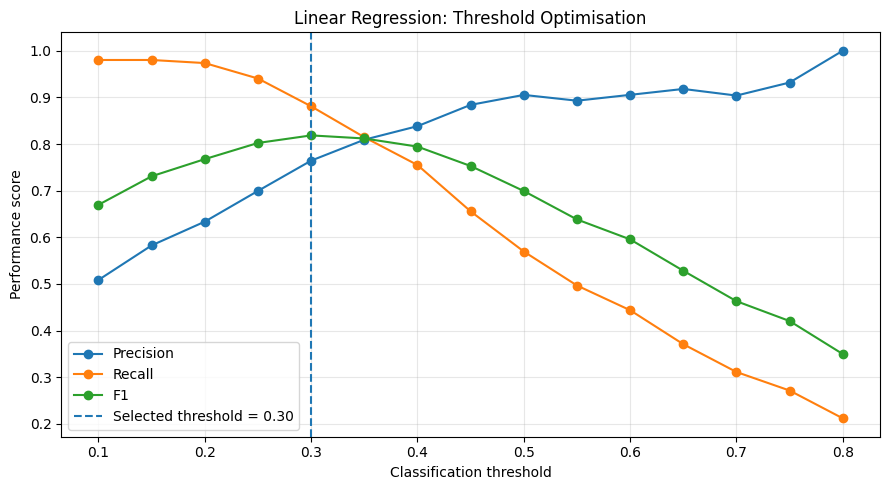

Saved: results/threshold_optimisation.png


In [54]:

# GENERATE THRESHOLD OPTIMISATION FIGURE

import matplotlib.pyplot as plt

# Reuse the threshold results calculated earlier.
plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

# Highlight the threshold selected using validation F1.
plt.axvline(
    best_linear_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_linear_threshold:.2f}"
)

plt.xlabel("Classification threshold")
plt.ylabel("Performance score")
plt.title("Linear Regression: Threshold Optimisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the figure inside the project repository.
output_file = project_dir / "results" / "threshold_optimisation.png"
output_file.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_file.relative_to(project_dir))


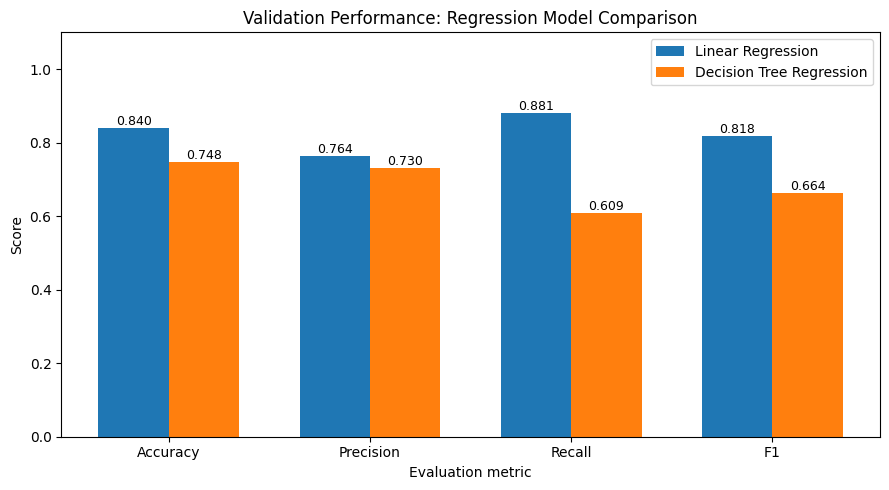

Saved: results/model_comparison.png


In [55]:
# GENERATE REGRESSION MODEL COMPARISON FIGURE

import numpy as np
import matplotlib.pyplot as plt

# Use the exported results already in memory.
validation_df = results_df[
    results_df["Dataset"] == "Validation"
].copy()

metrics = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metrics))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

for i, (_, model) in enumerate(validation_df.iterrows()):
    positions = x + (i - (len(validation_df) - 1) / 2) * bar_width

    bars = ax.bar(
        positions,
        [model[metric] for metric in metrics],
        bar_width,
        label=model["Model"]
    )

    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.3f}",
            (bar.get_x() + bar.get_width() / 2,
             bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.set_title("Validation Performance: Regression Model Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend()

plt.tight_layout()

output_file = project_dir / "results" / "model_comparison.png"
output_file.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_file.relative_to(project_dir))

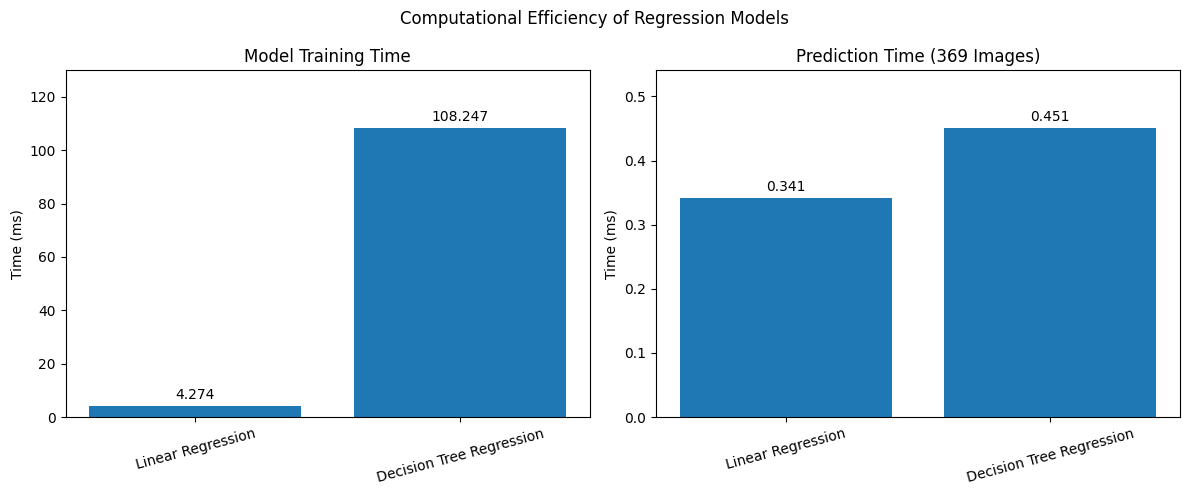

Saved: results/runtime_comparison.png


In [56]:
# GENERATE COMPUTATIONAL RUNTIME COMPARISON FIGURE

import matplotlib.pyplot as plt

# Reuse the runtime results calculated earlier.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = [
    ("Training time (ms)", "Model Training Time"),
    ("Prediction time (ms)", "Prediction Time (369 Images)")
]

for ax, (column, title) in zip(axes, metrics):
    bars = ax.bar(runtime_df["Model"], runtime_df[column])

    ax.set_title(title)
    ax.set_ylabel("Time (ms)")
    ax.tick_params(axis="x", rotation=15)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_ylim(0, runtime_df[column].max() * 1.2)

plt.suptitle("Computational Efficiency of Regression Models")
plt.tight_layout()

output_file = project_dir / "results" / "runtime_comparison.png"
output_file.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_file.relative_to(project_dir))

In [57]:
# GENERATE HTML DOCUMENTATION

import subprocess
import sys

docs_dir = project_dir / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

# Generate documentation from the project source modules.
subprocess.run(
    [
        sys.executable, "-m", "pdoc",
        "src.preprocessing",
        "src.data_loader",
        "src.regression",
        "src.evaluation",
        "-o", str(docs_dir)
    ],
    cwd=str(project_dir),
    check=True
)

print("Documentation saved:", docs_dir.relative_to(project_dir))
print("HTML files:", len(list(docs_dir.rglob("*.html"))))

Documentation saved: docs
HTML files: 9
